# Rural Water-Point Operational Status Prediction
## Stage 3 – Data Understanding and Exploratory Data Analysis

### Objective

The objective of this exploratory data analysis is to understand the structure, quality, distributions, and relationships within the Tanzania water-point dataset before preprocessing and model development.

The analysis focuses on:

- dataset structure and variable types,
- target-class distribution,
- missing and potentially hidden missing values,
- duplicate and unusual observations,
- categorical cardinality,
- numerical distributions and potential outliers,
- relationships between predictor variables and the target,
- feature redundancy,
- geographic patterns,
- and potential data-leakage risks.

No permanent preprocessing transformations are performed during this stage. Findings from the EDA will instead be used to justify preprocessing and feature-engineering decisions in Stage 4.

## 1. Dataset Loading and Integrity Verification

The predictor and target data are provided in separate files and are linked using the `id` field.

Before performing exploratory analysis, the datasets are inspected to verify:

- number of observations and variables,
- uniqueness of identifiers,
- consistency of IDs between the predictor and target files,
- successful one-to-one merging,
- and whether any records are lost during integration.

importing libraries


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

load the datasets

In [6]:
values = pd.read_csv("../data/raw/training_set_values.csv")
labels = pd.read_csv("../data/raw/training_set_labels.csv")

checking dimensions

In [7]:
print("Values shape:", values.shape)
print("Labels shape:", labels.shape)

Values shape: (59400, 40)
Labels shape: (59400, 2)


inspecting first records

In [8]:
values.head()

,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,payment_type,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,...,annually,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,...,never pay,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,...,per bucket,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe
3,67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,...,never pay,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe
4,19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,...,never pay,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe


In [9]:
labels.head()

,id,status_group
0,69572,functional
1,8776,functional
2,34310,functional
3,67743,non functional
4,19728,functional


In [10]:
values.tail()

,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,payment_type,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group
59395,60739,10.0,2013-05-03,Germany Republi,1210,CES,37.169807,-3.253847,Area Three Namba 27,0,...,per bucket,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe
59396,27263,4700.0,2011-05-07,Cefa-njombe,1212,Cefa,35.249991,-9.070629,Kwa Yahona Kuvala,0,...,annually,soft,good,enough,enough,river,river/lake,surface,communal standpipe,communal standpipe
59397,37057,0.0,2011-04-11,NaN,0,NaN,34.017087,-8.750434,Mashine,0,...,monthly,fluoride,fluoride,enough,enough,machine dbh,borehole,groundwater,hand pump,hand pump
59398,31282,0.0,2011-03-08,Malec,0,Musa,35.861315,-6.378573,Mshoro,0,...,never pay,soft,good,insufficient,insufficient,shallow well,shallow well,groundwater,hand pump,hand pump
59399,26348,0.0,2011-03-23,World Bank,191,World,38.104048,-6.747464,Kwa Mzee Lugawa,0,...,on failure,salty,salty,enough,enough,shallow well,shallow well,groundwater,hand pump,hand pump


In [11]:
labels.tail()

,id,status_group
59395,60739,functional
59396,27263,functional
59397,37057,functional
59398,31282,functional
59399,26348,functional


In [12]:
print(values.columns.tolist())

['id', 'amount_tsh', 'date_recorded', 'funder', 'gps_height', 'installer', 'longitude', 'latitude', 'wpt_name', 'num_private', 'basin', 'subvillage', 'region', 'region_code', 'district_code', 'lga', 'ward', 'population', 'public_meeting', 'recorded_by', 'scheme_management', 'scheme_name', 'permit', 'construction_year', 'extraction_type', 'extraction_type_group', 'extraction_type_class', 'management', 'management_group', 'payment', 'payment_type', 'water_quality', 'quality_group', 'quantity', 'quantity_group', 'source', 'source_type', 'source_class', 'waterpoint_type', 'waterpoint_type_group']


In [13]:
print(labels.columns.tolist())

['id', 'status_group']


In [14]:
print("Unique IDs in values:", values["id"].nunique())
print("Unique IDs in labels:", labels["id"].nunique())

print("Duplicate IDs in values:", values["id"].duplicated().sum())
print("Duplicate IDs in labels:", labels["id"].duplicated().sum())

Unique IDs in values: 59400
Unique IDs in labels: 59400
Duplicate IDs in values: 0
Duplicate IDs in labels: 0


In [15]:
ids_only_in_values = set(values["id"]) - set(labels["id"])
ids_only_in_labels = set(labels["id"]) - set(values["id"])

print("IDs only in values:", len(ids_only_in_values))
print("IDs only in labels:", len(ids_only_in_labels))

IDs only in values: 0
IDs only in labels: 0


In [16]:
df = values.merge(
    labels,
    on="id",
    how="inner",
    validate="one_to_one"
)

In [17]:
df.head()

,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,...,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,...,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,...,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe,functional
3,67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,...,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe,non functional
4,19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,...,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional


In [18]:
print(df.shape)

(59400, 41)


In [19]:
assert len(df) == len(values)
assert len(df) == len(labels)

print("Merge successful. No records lost.")

Merge successful. No records lost.


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 59400 entries, 0 to 59399
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     59400 non-null  int64  
 1   amount_tsh             59400 non-null  float64
 2   date_recorded          59400 non-null  str    
 3   funder                 55763 non-null  str    
 4   gps_height             59400 non-null  int64  
 5   installer              55745 non-null  str    
 6   longitude              59400 non-null  float64
 7   latitude               59400 non-null  float64
 8   wpt_name               59398 non-null  str    
 9   num_private            59400 non-null  int64  
 10  basin                  59400 non-null  str    
 11  subvillage             59029 non-null  str    
 12  region                 59400 non-null  str    
 13  region_code            59400 non-null  int64  
 14  district_code          59400 non-null  int64  
 15  lga          

In [21]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,59400.0,37115.131768,21453.128371,0.00000,18519.750000,37061.500000,55656.500000,7.424700e+04
amount_tsh,59400.0,317.650385,2997.574558,0.00000,0.000000,0.000000,20.000000,3.500000e+05
gps_height,59400.0,668.297239,693.116350,-90.00000,0.000000,369.000000,1319.250000,2.770000e+03
longitude,59400.0,34.077427,6.567432,0.00000,33.090347,34.908743,37.178387,4.034519e+01
latitude,59400.0,-5.706033,2.946019,-11.64944,-8.540621,-5.021597,-3.326156,-2.000000e-08
num_private,59400.0,0.474141,12.236230,0.00000,0.000000,0.000000,0.000000,1.776000e+03
region_code,59400.0,15.297003,17.587406,1.00000,5.000000,12.000000,17.000000,9.900000e+01
district_code,59400.0,5.629747,9.633649,0.00000,2.000000,3.000000,5.000000,8.000000e+01
population,59400.0,179.909983,471.482176,0.00000,0.000000,25.000000,215.000000,3.050000e+04
construction_year,59400.0,1300.652475,951.620547,0.00000,0.000000,1986.000000,2004.000000,2.013000e+03


In [22]:
df.describe(include="object").T

C:\Users\Wasika\AppData\Local\Temp\ipykernel_16796\1274302342.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object").T


,count,unique,top,freq
date_recorded,59400,356,2011-03-15,572
funder,55763,1896,Government Of Tanzania,9084
installer,55745,2145,DWE,17402
wpt_name,59398,37399,none,3563
basin,59400,9,Lake Victoria,10248
subvillage,59029,19287,Madukani,508
region,59400,21,Iringa,5294
lga,59400,125,Njombe,2503
ward,59400,2092,Igosi,307
public_meeting,56066,2,True,51011


In [23]:
print("Number of observations:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nData types:")
print(df.dtypes.value_counts())

Number of observations: 59400
Number of columns: 41

Data types:
str        29
int64       7
float64     3
object      2
Name: count, dtype: int64


In [24]:
X = df.drop(columns=["status_group"])

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()

print("Numerical predictors:", len(numeric_features))
print("Categorical predictors:", len(categorical_features))

Numerical predictors: 10
Categorical predictors: 30


C:\Users\Wasika\AppData\Local\Temp\ipykernel_16796\902198367.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include="object").columns.tolist()


### Key Observations

- The feature dataset contains 59,400 observations.
- The target dataset also contains 59,400 observations.
- The `id` field uniquely identifies each water-point record.
- No duplicate IDs were detected.
- The IDs in the feature and target datasets correspond correctly.
- The datasets were successfully merged without losing observations.
- The final analytical dataset contains the predictor variables together with the target variable `status_group`.

The integrity checks indicate that the dataset is structurally suitable for further exploratory analysis.

## 2. Variable Understanding and Analytical Roles

The dataset contains variables representing geographical location, infrastructure, management, payment arrangements, water characteristics, population, and construction information.

Raw data types alone are not sufficient to determine how variables should be analysed. For example, `region_code` and `district_code` are stored numerically but represent categorical geographic identifiers.

Therefore, variables are examined according to both their stored data type and their real-world meaning.

In [25]:
column_summary = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "non_null": df.notna().sum().values,
    "missing": df.isna().sum().values,
    "unique_values": df.nunique(dropna=True).values
})

column_summary

,column,dtype,non_null,missing,unique_values
0,id,int64,59400,0,59400
1,amount_tsh,float64,59400,0,98
2,date_recorded,str,59400,0,356
3,funder,str,55763,3637,1896
4,gps_height,int64,59400,0,2428
5,installer,str,55745,3655,2145
6,longitude,float64,59400,0,57516
7,latitude,float64,59400,0,57517
8,wpt_name,str,59398,2,37399
9,num_private,int64,59400,0,65


In [26]:
for col in df.columns:
    print(f"\n--- {col} ---")
    print("Data type:", df[col].dtype)
    print("Unique values:", df[col].nunique(dropna=True))
    print("Sample values:", df[col].dropna().unique()[:10])


--- id ---
Data type: int64
Unique values: 59400
Sample values: [69572  8776 34310 67743 19728  9944 19816 54551 53934 46144]

--- amount_tsh ---
Data type: float64
Unique values: 98
Sample values: [6000.    0.   25.   20.  200.  500.   50. 4000. 1500.    6.]

--- date_recorded ---
Data type: str
Unique values: 356
Sample values: <StringArray>
['2011-03-14', '2013-03-06', '2013-02-25', '2013-01-28', '2011-07-13',
 '2011-03-13', '2012-10-01', '2012-10-09', '2012-11-03', '2011-08-03']
Length: 10, dtype: str

--- funder ---
Data type: str
Unique values: 1896
Sample values: <StringArray>
[              'Roman',             'Grumeti',        'Lottery Club',
              'Unicef',         'Action In A', 'Mkinga Distric Coun',
                'Dwsp',               'Rwssp',            'Wateraid',
         'Isingiro Ho']
Length: 10, dtype: str

--- gps_height ---
Data type: int64
Unique values: 2428
Sample values: [1390 1399  686  263    0   62 1062 1368 1645 1703]

--- installer ---
Data typ

In [27]:
target = "status_group"

identifier_features = [
    "id"
]

date_features = [
    "date_recorded"
]

geographic_numeric_features = [
    "longitude",
    "latitude",
    "gps_height"
]

numeric_features = [
    "amount_tsh",
    "gps_height",
    "longitude",
    "latitude",
    "num_private",
    "population",
    "construction_year"
]

categorical_code_features = [
    "region_code",
    "district_code"
]

binary_categorical_features = [
    "public_meeting",
    "permit"
]

categorical_features = [
    "funder",
    "installer",
    "wpt_name",
    "basin",
    "subvillage",
    "region",
    "region_code",
    "district_code",
    "lga",
    "ward",
    "public_meeting",
    "recorded_by",
    "scheme_management",
    "scheme_name",
    "permit",
    "extraction_type",
    "extraction_type_group",
    "extraction_type_class",
    "management",
    "management_group",
    "payment",
    "payment_type",
    "water_quality",
    "quality_group",
    "quantity",
    "quantity_group",
    "source",
    "source_type",
    "source_class",
    "waterpoint_type",
    "waterpoint_type_group"
]

In [28]:
cardinality = (
    df[categorical_features]
    .nunique(dropna=True)
    .sort_values(ascending=False)
)

cardinality

wpt_name                 37399
subvillage               19287
scheme_name               2695
installer                 2145
ward                      2092
funder                    1896
lga                        125
region_code                 27
region                      21
district_code               20
extraction_type             18
extraction_type_group       13
management                  12
scheme_management           11
source                      10
basin                        9
water_quality                8
payment_type                 7
source_type                  7
waterpoint_type              7
extraction_type_class        7
payment                      7
waterpoint_type_group        6
quality_group                6
management_group             5
quantity_group               5
quantity                     5
source_class                 3
public_meeting               2
permit                       2
recorded_by                  1
dtype: int64

In [29]:
cardinality_df = pd.DataFrame({
    "feature": cardinality.index,
    "unique_categories": cardinality.values
})

cardinality_df

,feature,unique_categories
0,wpt_name,37399
1,subvillage,19287
2,scheme_name,2695
3,installer,2145
4,ward,2092
5,funder,1896
6,lga,125
7,region_code,27
8,region,21
9,district_code,20


In [30]:
print(df["date_recorded"].head())
print(df["date_recorded"].dtype)

0    2011-03-14
1    2013-03-06
2    2013-02-25
3    2013-01-28
4    2011-07-13
Name: date_recorded, dtype: str
str


In [31]:
date_recorded_eda = pd.to_datetime(
    df["date_recorded"],
    errors="coerce"
)

print("Earliest date:", date_recorded_eda.min())
print("Latest date:", date_recorded_eda.max())
print("Invalid dates:", date_recorded_eda.isna().sum())

Earliest date: 2002-10-14 00:00:00
Latest date: 2013-12-03 00:00:00
Invalid dates: 0


In [32]:
date_recorded_eda.dt.year.value_counts().sort_index()

date_recorded
2002        1
2004       30
2011    28674
2012     6424
2013    24271
Name: count, dtype: int64

In [33]:
df[["extraction_type","extraction_type_group","extraction_type_class"]]

,extraction_type,extraction_type_group,extraction_type_class
0,gravity,gravity,gravity
1,gravity,gravity,gravity
2,gravity,gravity,gravity
3,submersible,submersible,submersible
4,gravity,gravity,gravity
...,...,...,...
59395,gravity,gravity,gravity
59396,gravity,gravity,gravity
59397,swn 80,swn 80,handpump
59398,nira/tanira,nira/tanira,handpump


### Key Observations

The dataset contains a mixture of:

- numerical variables,
- nominal categorical variables,
- binary categorical variables,
- geographic variables,
- temporal variables,
- categorical codes,
- and identifier-like variables.

The dataset is predominantly categorical.

Several variables have very high cardinality, including:

- `wpt_name`,
- `subvillage`,
- `scheme_name`,
- `installer`,
- `ward`,
- and `funder`.

The dataset also contains several related feature families representing the same underlying characteristic at different levels of detail, including:

- `extraction_type`, `extraction_type_group`, and `extraction_type_class`,
- `source`, `source_type`, and `source_class`,
- `management` and `management_group`,
- `quantity` and `quantity_group`,
- `water_quality` and `quality_group`,
- `waterpoint_type` and `waterpoint_type_group`,
- `payment` and `payment_type`.

These relationships will later be investigated for redundancy before modelling.

## 3. Target Variable and Class Distribution

The prediction target is `status_group`, representing the observed operational condition of each water point.

The three target classes are:

- `functional`,
- `functional needs repair`,
- `non functional`.

The target distribution is analysed to determine whether class imbalance may affect model training and evaluation.

In [34]:
print(df["status_group"].unique())
print("Number of classes:", df["status_group"].nunique())
print("Missing target values:", df["status_group"].isna().sum())

<StringArray>
['functional', 'non functional', 'functional needs repair']
Length: 3, dtype: str
Number of classes: 3
Missing target values: 0


In [35]:
target_counts = df["status_group"].value_counts()

print(target_counts)

status_group
functional                 32259
non functional             22824
functional needs repair     4317
Name: count, dtype: int64


In [36]:
target_percentages = (
    df["status_group"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(target_percentages)

status_group
functional                 54.31
non functional             38.42
functional needs repair     7.27
Name: proportion, dtype: float64


Visualise the target distribution

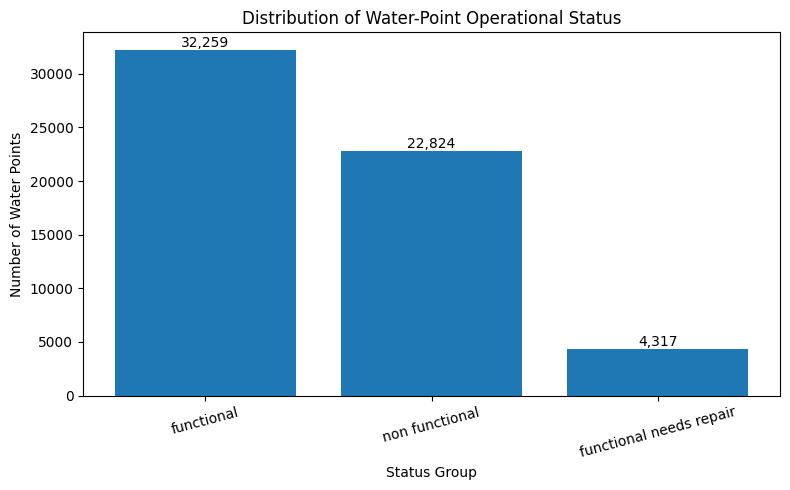

In [37]:
target_counts = df["status_group"].value_counts()

plt.figure(figsize=(8, 5))
bars = plt.bar(target_counts.index, target_counts.values)

plt.title("Distribution of Water-Point Operational Status")
plt.xlabel("Status Group")
plt.ylabel("Number of Water Points")
plt.xticks(rotation=15)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

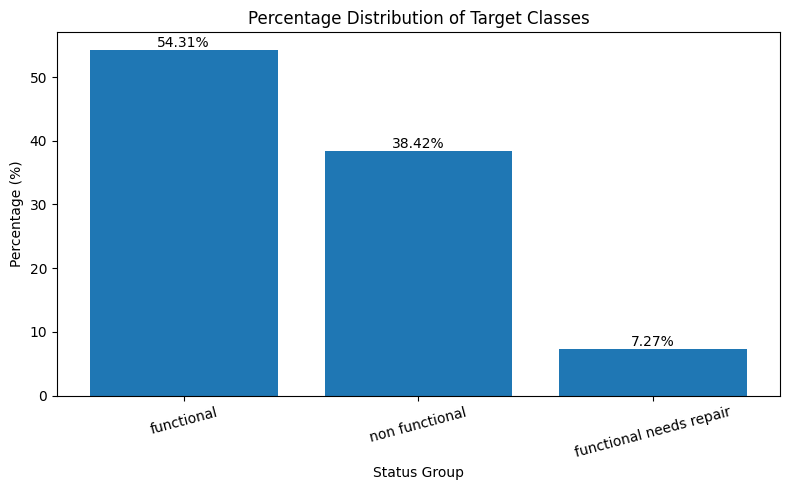

In [38]:
target_pct = (
    df["status_group"]
    .value_counts(normalize=True)
    .mul(100)
)

plt.figure(figsize=(8, 5))
bars = plt.bar(target_pct.index, target_pct.values)

plt.title("Percentage Distribution of Target Classes")
plt.xlabel("Status Group")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=15)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [39]:
majority_baseline = (
    df["status_group"]
    .value_counts(normalize=True)
    .max()
)

print(f"Majority-class baseline accuracy: {majority_baseline:.2%}")

Majority-class baseline accuracy: 54.31%


### Key Observations

The target variable contains three classes:

- **Functional:** 32,259 observations (54.31%)
- **Non-functional:** 22,824 observations (38.42%)
- **Functional needs repair:** 4,317 observations (7.27%)

The dataset therefore exhibits moderate class imbalance, particularly for the `functional needs repair` class.

The minority class still contains more than 4,000 observations, providing a meaningful number of examples for model training.

However, overall accuracy alone may not adequately represent model performance because a model could perform poorly on the minority class while still achieving relatively high accuracy.

Later model evaluation should therefore consider class-sensitive metrics such as:

- precision,
- recall,
- macro F1-score,
- weighted F1-score,
- and the confusion matrix.

## 4. Missing and Potentially Missing Values

Missing-data analysis considers both explicit missing values represented as `NaN` and potentially hidden missing values encoded using values such as `0`, `unknown`, `none`, or similar categories.

These patterns are investigated before deciding how missing information should be handled during preprocessing.

In [40]:
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].sort_values("missing_percentage", ascending=False)

missing_summary

,missing_count,missing_percentage
scheme_name,28810,48.50
scheme_management,3878,6.53
installer,3655,6.15
funder,3637,6.12
public_meeting,3334,5.61
permit,3056,5.14
subvillage,371,0.62
wpt_name,2,0.00


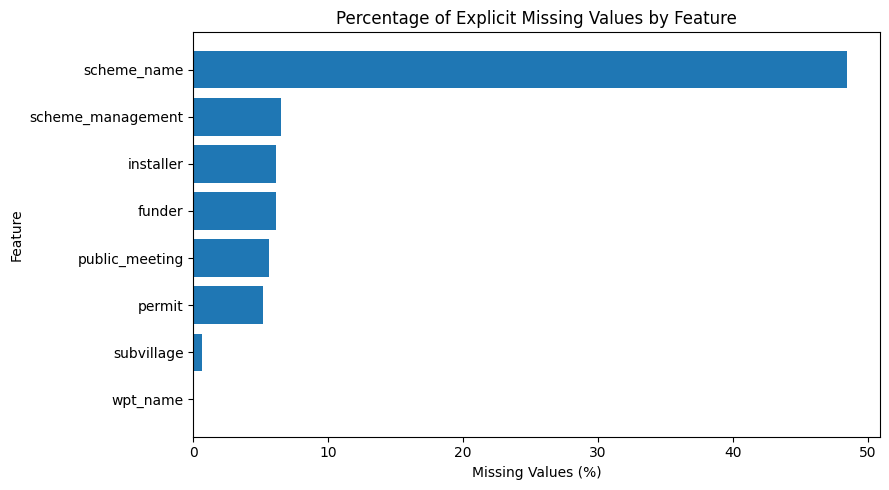

In [41]:
plt.figure(figsize=(9, 5))

plt.barh(
    missing_summary.index,
    missing_summary["missing_percentage"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.title("Percentage of Explicit Missing Values by Feature")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [42]:
rows_with_missing = df.isnull().any(axis=1).sum()

print("Rows containing at least one missing value:", rows_with_missing)
print(
    "Percentage:",
    round(rows_with_missing / len(df) * 100, 2),
    "%"
)

Rows containing at least one missing value: 32229
Percentage: 54.26 %


In [43]:
missing_per_row = df.isnull().sum(axis=1)

print(missing_per_row.value_counts().sort_index())

0    27171
1    22595
2     5600
3     3280
4      668
5       80
6        6
Name: count, dtype: int64


In [44]:
numeric_cols = df.select_dtypes(include=np.number).columns

zero_summary = []

for col in numeric_cols:
    zero_count = (df[col] == 0).sum()
    
    zero_summary.append({
        "feature": col,
        "zero_count": zero_count,
        "zero_percentage": round(
            zero_count / len(df) * 100, 2
        )
    })

zero_summary = pd.DataFrame(zero_summary)

zero_summary.sort_values(
    "zero_percentage",
    ascending=False
)

,feature,zero_count,zero_percentage
5,num_private,58643,98.73
1,amount_tsh,41639,70.10
8,population,21381,35.99
9,construction_year,20709,34.86
2,gps_height,20438,34.41
3,longitude,1812,3.05
7,district_code,23,0.04
0,id,1,0.00
4,latitude,0,0.00
6,region_code,0,0.00


In [45]:
for col in df.select_dtypes(include="object").columns:
    values_lower = (
        df[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    suspicious = values_lower.isin(
        ["unknown", "none", "0", "not known", "n/a"]
    )

    count = suspicious.sum()

    if count > 0:
        print(
            col,
            "->",
            count,
            f"({count / len(df) * 100:.2f}%)"
        )

funder -> 808 (1.36%)
installer -> 822 (1.38%)
wpt_name -> 3586 (6.04%)


C:\Users\Wasika\AppData\Local\Temp\ipykernel_16796\4178422707.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


scheme_name -> 33 (0.06%)
management -> 561 (0.94%)
management_group -> 561 (0.94%)
payment -> 8157 (13.73%)
payment_type -> 8157 (13.73%)
water_quality -> 1876 (3.16%)
quality_group -> 1876 (3.16%)
quantity -> 789 (1.33%)
quantity_group -> 789 (1.33%)
source -> 66 (0.11%)
source_class -> 278 (0.47%)


In [46]:
columns_with_missing = [
    col for col in df.columns
    if df[col].isnull().sum() > 0
]

missing_by_target = pd.DataFrame()

for col in columns_with_missing:
    missing_by_target[col] = (
        df.groupby("status_group")[col]
        .apply(lambda x: x.isnull().mean() * 100)
    )

missing_by_target.round(2)

,funder,installer,wpt_name,subvillage,public_meeting,scheme_management,scheme_name,permit
status_group,,,,,,,,
functional,6.14,6.20,0.00,0.64,5.20,5.81,46.19,5.19
functional needs repair,10.12,10.19,0.00,0.02,3.61,5.17,47.12,6.95
non functional,5.34,5.32,0.01,0.72,6.57,7.80,52.03,4.75


In [47]:
suspected_zero_features = [
    "construction_year",
    "population",
    "gps_height",
    "amount_tsh",
    "longitude",
    "num_private"
]

zero_by_target = pd.DataFrame()

for col in suspected_zero_features:
    zero_by_target[col] = (
        df.groupby("status_group")[col]
        .apply(lambda x: (x == 0).mean() * 100)
    )

zero_by_target.round(2)

,construction_year,population,gps_height,amount_tsh,longitude,num_private
status_group,,,,,,
functional,32.72,34.95,32.45,61.09,2.70,98.57
functional needs repair,41.44,41.12,40.84,70.60,8.94,98.89
non functional,36.65,36.51,35.95,82.74,2.44,98.91


### Key Observations

Explicit missingness is concentrated in several variables.

The most significant issue is `scheme_name`, with approximately 48.5% missing observations.

Moderate missingness is also present in:

- `scheme_management`,
- `installer`,
- `funder`,
- `public_meeting`,
- and `permit`.

Several numerical variables also contain unusually large numbers of zero values.

Important examples include:

- `construction_year`,
- `population`,
- `gps_height`,
- `amount_tsh`,
- `longitude`,
- and `num_private`.

A zero value cannot represent a valid construction year, indicating that zero is likely being used to represent unavailable information in `construction_year`.

Similarly, longitude values equal to zero are inconsistent with the main geographic range and likely represent invalid or unavailable coordinates.

However, zero values in variables such as `population`, `gps_height`, and `amount_tsh` cannot automatically be classified as missing because zero may be meaningful in some contexts.

Categorical variables also contain explicit values such as `unknown`, indicating that missing information may already be represented as a category.

Therefore, missing values should be handled on a feature-by-feature basis rather than using a single deletion or imputation strategy.

## 5. Duplicate Records, Uniqueness, and Categorical Cardinality

Duplicate observations and variable uniqueness are investigated to identify:

- duplicated predictor profiles,
- constant variables,
- near-constant variables,
- identifier-like features,
- and high-cardinality categorical variables.

High-cardinality variables are particularly important because direct one-hot encoding may create a very large and sparse feature space.

In [48]:
print("Exact duplicated rows:", df.duplicated().sum())

Exact duplicated rows: 0


In [49]:
feature_cols = [
    col for col in df.columns
    if col not in ["id", "status_group"]
]

duplicate_feature_rows = df.duplicated(
    subset=feature_cols,
    keep=False
)

print(
    "Rows involved in duplicated predictor profiles:",
    duplicate_feature_rows.sum()
)

print(
    "Extra duplicated predictor records:",
    df.duplicated(subset=feature_cols).sum()
)

Rows involved in duplicated predictor profiles: 72
Extra duplicated predictor records: 37


In [50]:
duplicate_groups = (
    df.groupby(feature_cols, dropna=False)["status_group"]
      .agg(
          group_size="size",
          target_classes="nunique"
      )
)
duplicate_groups = duplicate_groups[
    duplicate_groups["group_size"] > 1
]

print(duplicate_groups["target_classes"].value_counts())

target_classes
1    34
2     1
Name: count, dtype: int64


In [51]:
unique_counts = df.nunique(dropna=False)

constant_features = unique_counts[
    unique_counts == 1
]

constant_features

recorded_by    1
dtype: int64

In [52]:
dominance_summary = []

for col in df.columns:
    top_count = df[col].value_counts(
        dropna=False
    ).iloc[0]

    dominance_summary.append({
        "feature": col,
        "most_common_count": top_count,
        "most_common_percentage":
            round(top_count / len(df) * 100, 2)
    })

dominance_summary = (
    pd.DataFrame(dominance_summary)
      .sort_values(
          "most_common_percentage",
          ascending=False
      )
)

dominance_summary.head(15)

,feature,most_common_count,most_common_percentage
19,recorded_by,59400,100.00
9,num_private,58643,98.73
28,management_group,52490,88.37
18,public_meeting,51011,85.88
32,quality_group,50818,85.55
31,water_quality,50818,85.55
37,source_class,45794,77.09
1,amount_tsh,41639,70.10
27,management,40507,68.19
22,permit,38852,65.41


In [53]:
categorical_cols = df.select_dtypes(
    include=["object", "bool"]
).columns.tolist()

categorical_cols = [
    c for c in categorical_cols
    if c != "status_group"
]

cardinality = pd.DataFrame({
    "feature": categorical_cols,
    "unique_categories": [
        df[c].nunique(dropna=True)
        for c in categorical_cols
    ]
})

cardinality = cardinality.sort_values(
    "unique_categories",
    ascending=False
)

cardinality

C:\Users\Wasika\AppData\Local\Temp\ipykernel_16796\960645654.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


,feature,unique_categories
3,wpt_name,37399
5,subvillage,19287
12,scheme_name,2695
2,installer,2145
8,ward,2092
1,funder,1896
0,date_recorded,356
7,lga,125
6,region,21
14,extraction_type,18


In [54]:
cardinality["cardinality_ratio"] = (
    cardinality["unique_categories"] /
    len(df)
).round(4)

cardinality

,feature,unique_categories,cardinality_ratio
3,wpt_name,37399,0.6296
5,subvillage,19287,0.3247
12,scheme_name,2695,0.0454
2,installer,2145,0.0361
8,ward,2092,0.0352
1,funder,1896,0.0319
0,date_recorded,356,0.0060
7,lga,125,0.0021
6,region,21,0.0004
14,extraction_type,18,0.0003


In [55]:
high_cardinality_features = [
    "wpt_name",
    "subvillage",
    "scheme_name",
    "installer",
    "ward",
    "funder"
]

rare_summary = []

for col in high_cardinality_features:
    counts = df[col].value_counts(dropna=True)

    rare_summary.append({
        "feature": col,
        "unique_categories": len(counts),
        "categories_occurring_once":
            (counts == 1).sum(),
        "categories_occurring_5_or_less":
            (counts <= 5).sum()
    })

pd.DataFrame(rare_summary)

,feature,unique_categories,categories_occurring_once,categories_occurring_5_or_less
0,wpt_name,37399,32928,36860
1,subvillage,19287,9424,17316
2,scheme_name,2695,712,1513
3,installer,2145,1098,1594
4,ward,2092,30,223
5,funder,1896,974,1373


In [56]:
print(df["id"].nunique())
print(len(df))

59400
59400


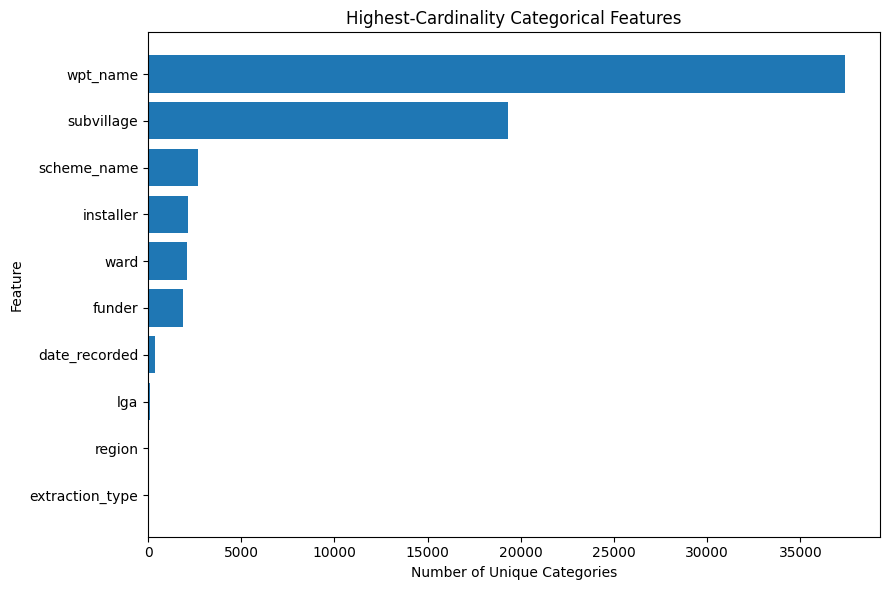

In [57]:
plot_cardinality = cardinality.head(10)

plt.figure(figsize=(9, 6))

plt.barh(
    plot_cardinality["feature"],
    plot_cardinality["unique_categories"]
)

plt.xlabel("Number of Unique Categories")
plt.ylabel("Feature")
plt.title(
    "Highest-Cardinality Categorical Features"
)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Key Observations

No completely duplicated records were found when all variables were considered.

After excluding the unique `id` field, only a very small number of observations shared identical predictor profiles, meaning duplication is not a major issue in the dataset.

The variable `recorded_by` contains only one unique value and therefore provides no discriminatory information.

The `id` field uniquely identifies every observation and should be treated as a record identifier rather than a predictive feature.

Several categorical variables exhibit extremely high cardinality. In particular:

- `wpt_name` contains tens of thousands of unique values,
- `subvillage` also contains a very large number of categories,
- while `installer`, `funder`, `ward`, and `scheme_name` contain thousands of categories.

Many categories occur only once or a small number of times.

These variables may require rare-category grouping, alternative encoding approaches, feature selection, or removal during preprocessing.

## 6. Numerical Feature Distribution and Outlier Analysis

Numerical variables are analysed to understand their distributions, ranges, skewness, unusual values, and potential outliers.

Statistical outliers are not automatically treated as errors because extreme values may represent genuine real-world observations.

Variables such as `id`, `region_code`, and `district_code` are excluded from continuous numerical analysis because they represent identifiers or categorical codes.

In [58]:
numerical_features = [
    "amount_tsh",
    "gps_height",
    "longitude",
    "latitude",
    "num_private",
    "population",
    "construction_year"
]

In [59]:
numerical_summary = df[numerical_features].describe().T

numerical_summary

,count,mean,std,min,25%,50%,75%,max
amount_tsh,59400.0,317.650385,2997.574558,0.00000,0.000000,0.000000,20.000000,3.500000e+05
gps_height,59400.0,668.297239,693.116350,-90.00000,0.000000,369.000000,1319.250000,2.770000e+03
longitude,59400.0,34.077427,6.567432,0.00000,33.090347,34.908743,37.178387,4.034519e+01
latitude,59400.0,-5.706033,2.946019,-11.64944,-8.540621,-5.021597,-3.326156,-2.000000e-08
num_private,59400.0,0.474141,12.236230,0.00000,0.000000,0.000000,0.000000,1.776000e+03
population,59400.0,179.909983,471.482176,0.00000,0.000000,25.000000,215.000000,3.050000e+04
construction_year,59400.0,1300.652475,951.620547,0.00000,0.000000,1986.000000,2004.000000,2.013000e+03


In [60]:
quantiles = df[numerical_features].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

quantiles

,0.01,0.05,0.25,0.50,0.75,0.95,0.99
amount_tsh,0.000000,0.00000,0.000000,0.000000,20.000000,1200.000000,5.000000e+03
gps_height,-22.000000,0.00000,0.000000,369.000000,1319.250000,1797.000000,2.142000e+03
longitude,0.000000,30.04066,33.090347,34.908743,37.178387,39.133240,3.976841e+01
latitude,-11.112547,-10.58555,-8.540621,-5.021597,-3.326156,-1.408872,-2.000000e-08
num_private,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,5.000000e+00
population,0.000000,0.00000,0.000000,25.000000,215.000000,680.000000,2.000000e+03
construction_year,0.000000,0.00000,0.000000,1986.000000,2004.000000,2010.000000,2.012000e+03


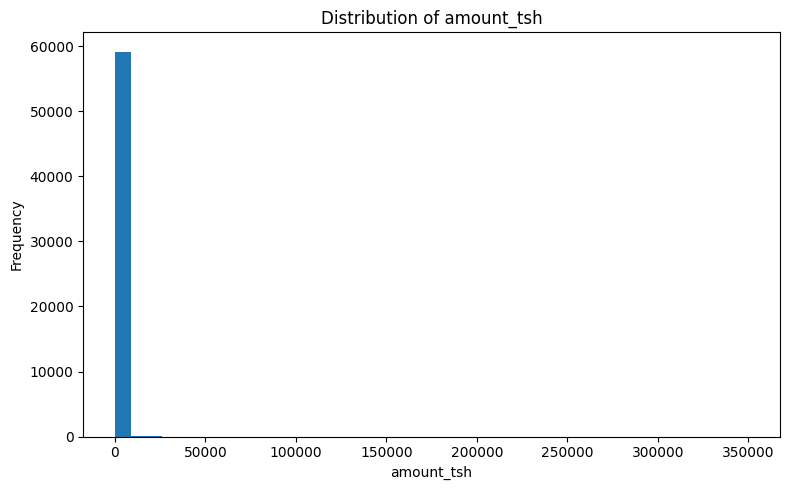

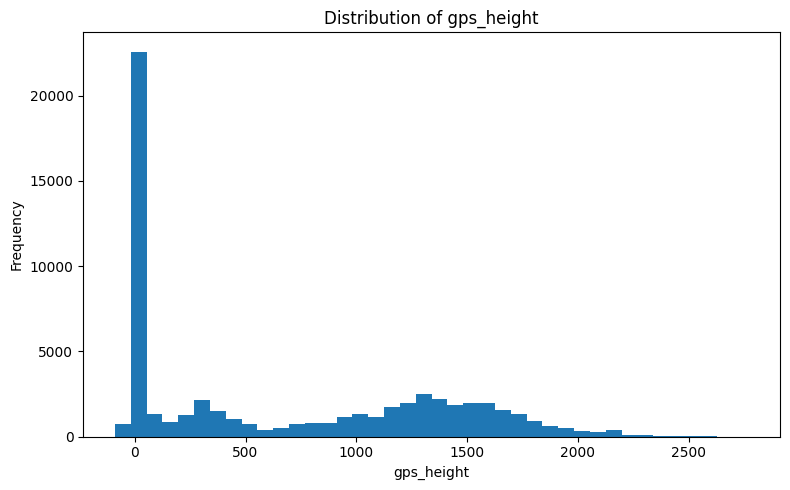

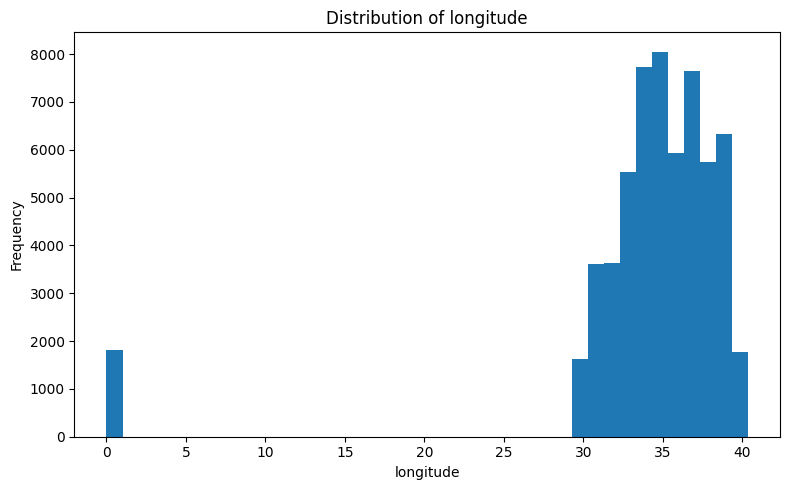

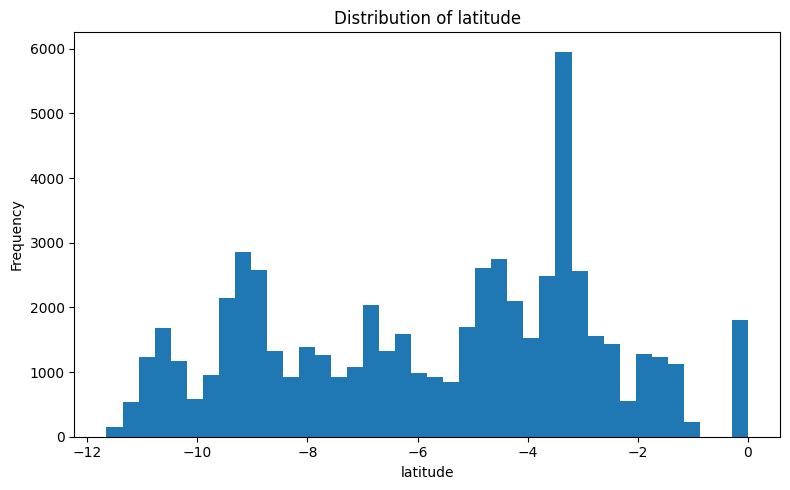

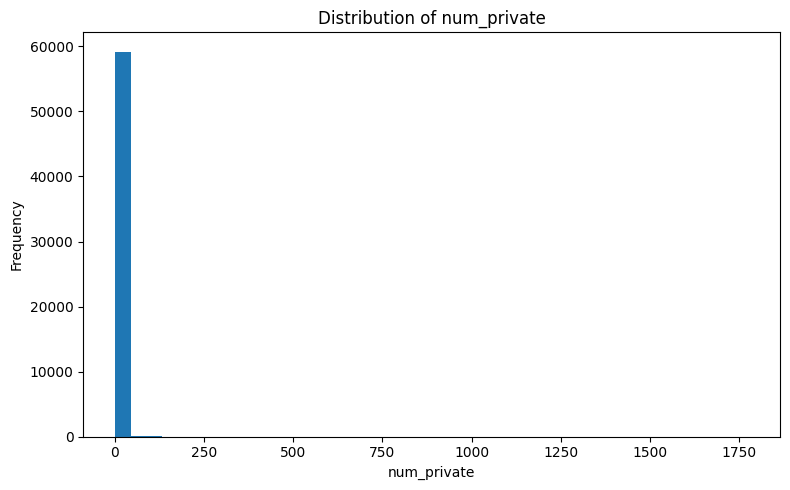

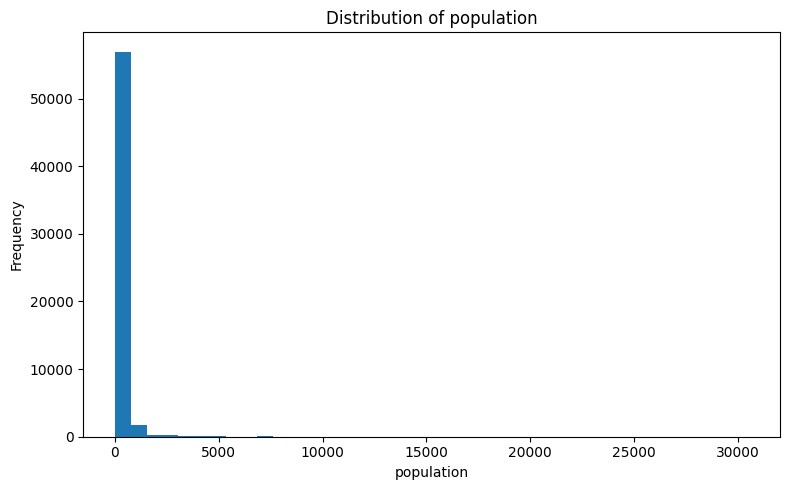

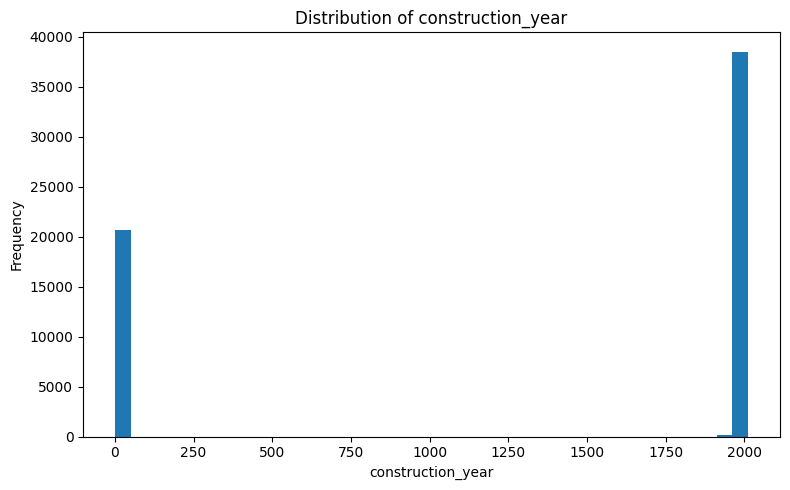

In [61]:
for col in numerical_features:
    plt.figure(figsize=(8, 5))

    plt.hist(
        df[col].dropna(),
        bins=40
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

In [62]:
df["amount_tsh"].describe()

count     59400.000000
mean        317.650385
std        2997.574558
min           0.000000
25%           0.000000
50%           0.000000
75%          20.000000
max      350000.000000
Name: amount_tsh, dtype: float64

In [63]:
df.loc[
    df["amount_tsh"] > 0,
    "amount_tsh"
].describe()

count     17761.000000
mean       1062.351942
std        5409.344940
min           0.200000
25%          50.000000
50%         250.000000
75%        1000.000000
max      350000.000000
Name: amount_tsh, dtype: float64

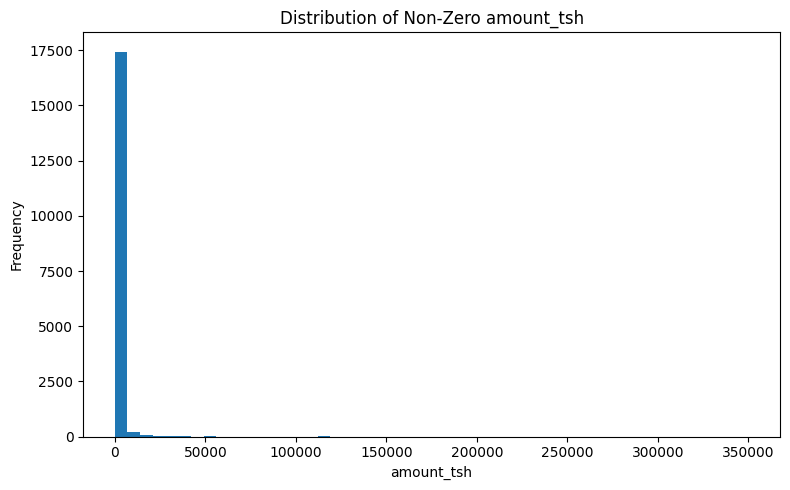

In [64]:
plt.figure(figsize=(8, 5))

plt.hist(
    df.loc[df["amount_tsh"] > 0, "amount_tsh"],
    bins=50
)

plt.title("Distribution of Non-Zero amount_tsh")
plt.xlabel("amount_tsh")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

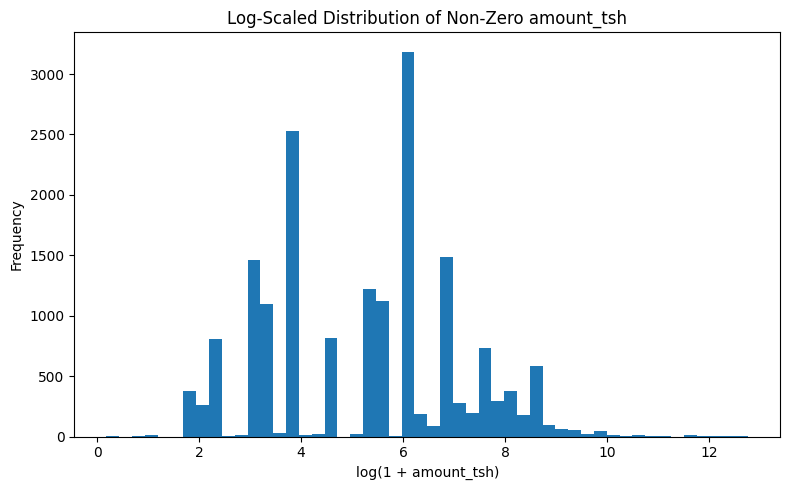

In [65]:
plt.figure(figsize=(8, 5))

plt.hist(
    np.log1p(
        df.loc[df["amount_tsh"] > 0, "amount_tsh"]
    ),
    bins=50
)

plt.title("Log-Scaled Distribution of Non-Zero amount_tsh")
plt.xlabel("log(1 + amount_tsh)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [66]:
df["population"].describe()

count    59400.000000
mean       179.909983
std        471.482176
min          0.000000
25%          0.000000
50%         25.000000
75%        215.000000
max      30500.000000
Name: population, dtype: float64

In [67]:
df.loc[
    df["population"] > 0,
    "population"
].describe(
    percentiles=[0.90, 0.95, 0.99]
)

count    38019.000000
mean       281.087167
std        564.687660
min          1.000000
90%        600.000000
95%        897.000000
99%       2500.000000
max      30500.000000
Name: population, dtype: float64

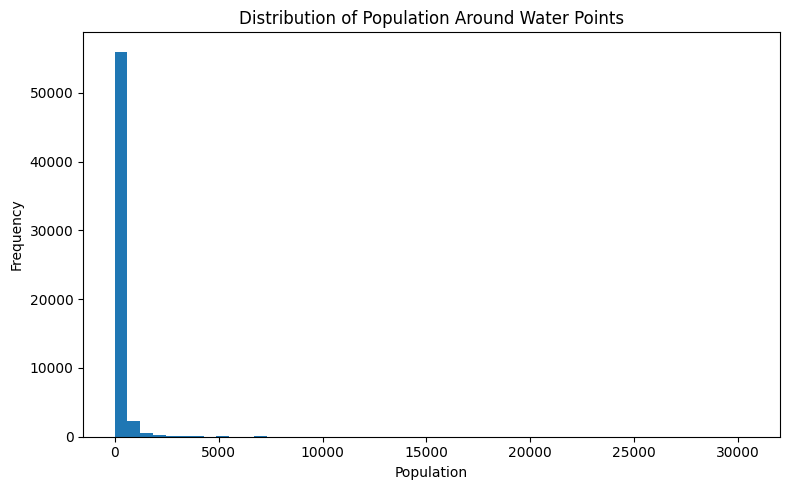

In [68]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["population"],
    bins=50
)

plt.title("Distribution of Population Around Water Points")
plt.xlabel("Population")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

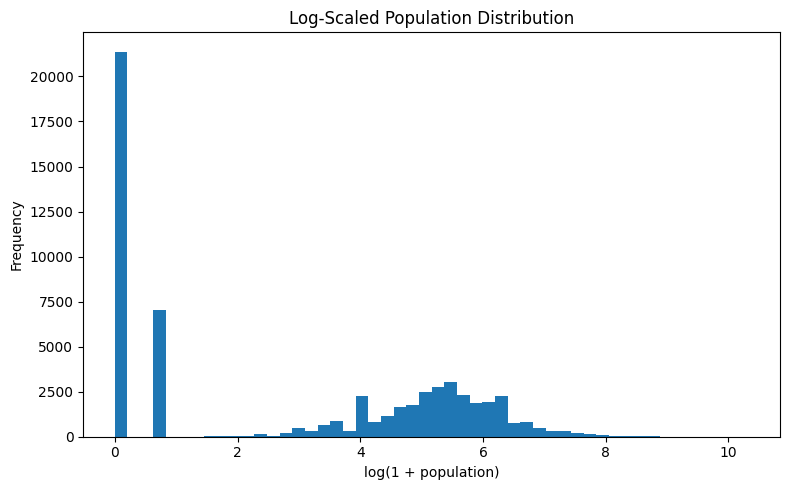

In [69]:
plt.figure(figsize=(8, 5))

plt.hist(
    np.log1p(df["population"]),
    bins=50
)

plt.title("Log-Scaled Population Distribution")
plt.xlabel("log(1 + population)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [70]:
df["construction_year"].value_counts().sort_index()

construction_year
0       20709
1960      102
1961       21
1962       30
1963       85
1964       40
1965       19
1966       17
1967       88
1968       77
1969       59
1970      411
1971      145
1972      708
1973      184
1974      676
1975      437
1976      414
1977      202
1978     1037
1979      192
1980      811
1981      238
1982      744
1983      488
1984      779
1985      945
1986      434
1987      302
1988      521
1989      316
1990      954
1991      324
1992      640
1993      608
1994      738
1995     1014
1996      811
1997      644
1998      966
1999      979
2000     2091
2001      540
2002     1075
2003     1286
2004     1123
2005     1011
2006     1471
2007     1587
2008     2613
2009     2533
2010     2645
2011     1256
2012     1084
2013      176
Name: count, dtype: int64

In [71]:
valid_years = df.loc[
    df["construction_year"] > 0,
    "construction_year"
]

print(valid_years.min())
print(valid_years.max())
print(valid_years.median())

1960
2013
2000.0


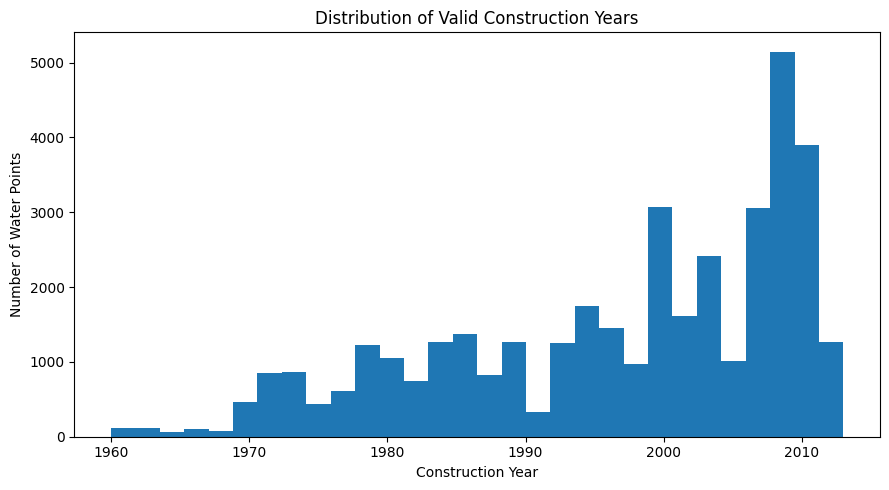

In [72]:
plt.figure(figsize=(9, 5))

plt.hist(
    valid_years,
    bins=30
)

plt.title("Distribution of Valid Construction Years")
plt.xlabel("Construction Year")
plt.ylabel("Number of Water Points")

plt.tight_layout()
plt.show()

In [73]:
df.loc[
    df["longitude"] == 0,
    ["longitude", "latitude"]
].head(20)

,longitude,latitude
21,0.0,-2.000000e-08
53,0.0,-2.000000e-08
168,0.0,-2.000000e-08
177,0.0,-2.000000e-08
253,0.0,-2.000000e-08
256,0.0,-2.000000e-08
285,0.0,-2.000000e-08
301,0.0,-2.000000e-08
306,0.0,-2.000000e-08
321,0.0,-2.000000e-08


In [74]:
print(
    df.loc[df["longitude"] != 0, "longitude"].min()
)

print(
    df.loc[df["longitude"] != 0, "longitude"].max()
)

29.6071219
40.34519307


In [75]:
invalid_coordinate_mask = (
    (df["longitude"] == 0) &
    (df["latitude"].abs() < 0.001)
)

print(
    "Likely invalid coordinate pairs:",
    invalid_coordinate_mask.sum()
)

Likely invalid coordinate pairs: 1812


In [76]:
df["gps_height"].describe()

count    59400.000000
mean       668.297239
std        693.116350
min        -90.000000
25%          0.000000
50%        369.000000
75%       1319.250000
max       2770.000000
Name: gps_height, dtype: float64

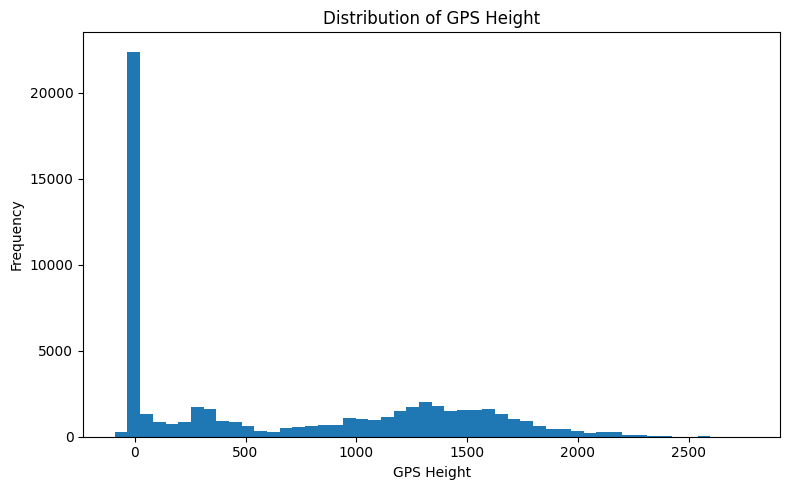

In [77]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["gps_height"],
    bins=50
)

plt.title("Distribution of GPS Height")
plt.xlabel("GPS Height")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [78]:
df["num_private"].value_counts().head(20)

num_private
0      58643
6         81
1         73
5         46
8         46
32        40
45        36
15        35
39        30
93        28
3         27
7         26
2         23
65        22
47        21
102       20
4         20
17        17
80        15
20        14
Name: count, dtype: int64

In [79]:
df.loc[
    df["num_private"] > 0,
    "num_private"
].describe()

count     757.000000
mean       37.204756
std       101.958683
min         1.000000
25%         6.000000
50%        15.000000
75%        42.000000
max      1776.000000
Name: num_private, dtype: float64

In [80]:
outlier_summary = []

for col in numerical_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        "feature": col,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_percentage":
            round(outlier_count / len(df) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
0,amount_tsh,-30.000000,50.000000,11161,18.79
1,gps_height,-1978.875000,3298.125000,0,0.00
2,longitude,26.958289,43.310445,1812,3.05
3,latitude,-16.362320,4.495543,0,0.00
4,num_private,0.000000,0.000000,757,1.27
5,population,-322.500000,537.500000,4383,7.38
6,construction_year,-3006.000000,5010.000000,0,0.00


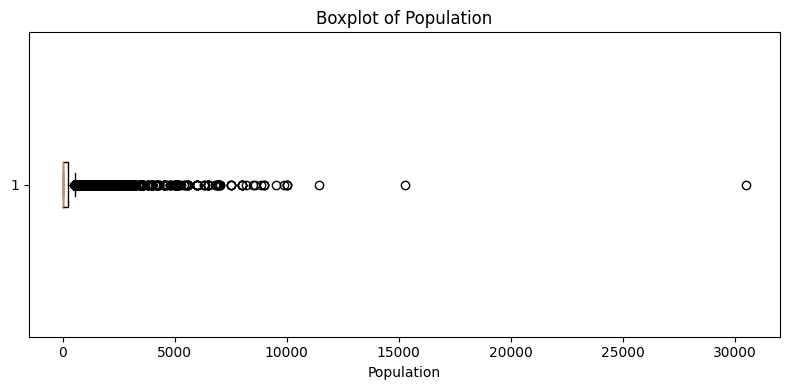

In [81]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    df["population"],
    vert=False
)

plt.title("Boxplot of Population")
plt.xlabel("Population")

plt.tight_layout()
plt.show()

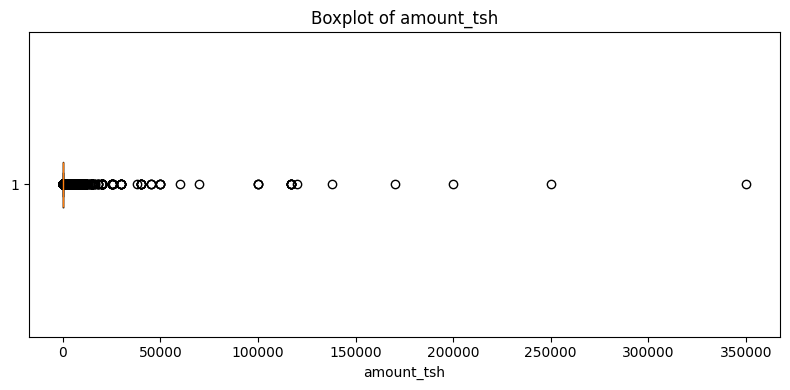

In [82]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    df["amount_tsh"],
    vert=False
)

plt.title("Boxplot of amount_tsh")
plt.xlabel("amount_tsh")

plt.tight_layout()
plt.show()

In [83]:
df[
    [
        "population",
        "region",
        "district_code",
        "status_group"
    ]
].sort_values(
    "population",
    ascending=False
).head(20)

,population,region,district_code,status_group
30537,30500,Tanga,3,functional
14308,15300,Manyara,5,functional needs repair
51398,11463,Pwani,2,functional
30231,10000,Mara,2,functional
56742,10000,Mara,1,functional
31363,10000,Rukwa,1,functional
12784,9865,Dar es Salaam,1,non functional
13725,9500,Arusha,3,functional needs repair
48725,9000,Mara,2,functional
51919,9000,Rukwa,1,non functional


In [84]:
df[
    [
        "amount_tsh",
        "region",
        "status_group"
    ]
].sort_values(
    "amount_tsh",
    ascending=False
).head(20)

,amount_tsh,region,status_group
10812,350000.0,Singida,functional
22191,250000.0,Pwani,functional
22817,200000.0,Tanga,functional
45067,170000.0,Pwani,functional
9961,138000.0,Pwani,functional
9917,120000.0,Kilimanjaro,functional
44381,117000.0,Iringa,functional
37459,117000.0,Iringa,functional
10615,117000.0,Iringa,functional
57811,117000.0,Iringa,non functional


### Key Observations

Several numerical variables exhibit highly skewed or zero-inflated distributions.

`amount_tsh` contains a large proportion of zero observations and is strongly right-skewed, with a small number of very large values.

`population` is also strongly right-skewed, with most water points serving relatively small populations while a small number serve very large populations.

Approximately one-third of `construction_year` values are recorded as zero. Valid non-zero construction years range from approximately 1960 to 2013, confirming that zero is likely being used to represent unavailable construction-year information.

A group of records contains longitude equal to zero together with latitude values extremely close to zero. These coordinates are inconsistent with the main geographic distribution and are likely invalid or unavailable location values.

`num_private` is almost entirely zero and its meaning is not clearly defined in the supplied feature documentation, making its usefulness uncertain.

IQR-based analysis identified several statistical outliers, particularly within `amount_tsh` and `population`. However, these values were not automatically removed because the underlying distributions are naturally skewed and statistical outliers may still represent valid observations.

## 7. Categorical Feature Distribution Analysis

Selected low- and medium-cardinality categorical variables are analysed to understand their category distributions.

Rather than plotting every categorical feature, the analysis focuses on variables representing important dimensions of the water-point system, including:

- water availability,
- extraction technology,
- infrastructure type,
- payment arrangements,
- water source,
- water quality,
- and geographic region.

High-cardinality variables were analysed separately during the cardinality analysis.

In [85]:
selected_categorical_features = [
    "basin",
    "region",
    "public_meeting",
    "scheme_management",
    "permit",
    "extraction_type_class",
    "management_group",
    "payment_type",
    "quality_group",
    "quantity",
    "source_class",
    "waterpoint_type_group"
]

frequency and percentage tables

In [86]:
for col in selected_categorical_features:
    counts = df[col].value_counts(dropna=False)

    percentages = (
        df[col]
        .value_counts(dropna=False, normalize=True)
        .mul(100)
        .round(2)
    )

    summary = pd.DataFrame({
        "count": counts,
        "percentage": percentages
    })

    print(f"\n--- {col} ---")
    display(summary)


--- basin ---


,count,percentage
basin,,
Lake Victoria,10248,17.25
Pangani,8940,15.05
Rufiji,7976,13.43
Internal,7785,13.11
Lake Tanganyika,6432,10.83
Wami / Ruvu,5987,10.08
Lake Nyasa,5085,8.56
Ruvuma / Southern Coast,4493,7.56
Lake Rukwa,2454,4.13



--- region ---


,count,percentage
region,,
Iringa,5294,8.91
Shinyanga,4982,8.39
Mbeya,4639,7.81
Kilimanjaro,4379,7.37
Morogoro,4006,6.74
Arusha,3350,5.64
Kagera,3316,5.58
Mwanza,3102,5.22
Kigoma,2816,4.74



--- public_meeting ---


,count,percentage
public_meeting,,
True,51011,85.88
False,5055,8.51
NaN,3334,5.61


... (14 outputs left out)


--- source_class ---


,count,percentage
source_class,,
groundwater,45794,77.09
surface,13328,22.44
unknown,278,0.47



--- waterpoint_type_group ---


,count,percentage
waterpoint_type_group,,
communal standpipe,34625,58.29
hand pump,17488,29.44
other,6380,10.74
improved spring,784,1.32
cattle trough,116,0.20
dam,7,0.01


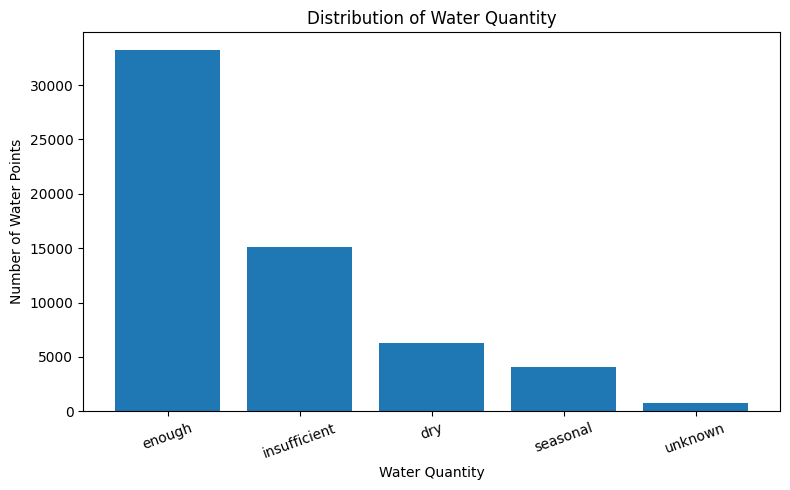

In [87]:
counts = df["quantity"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(counts.index, counts.values)

plt.title("Distribution of Water Quantity")
plt.xlabel("Water Quantity")
plt.ylabel("Number of Water Points")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

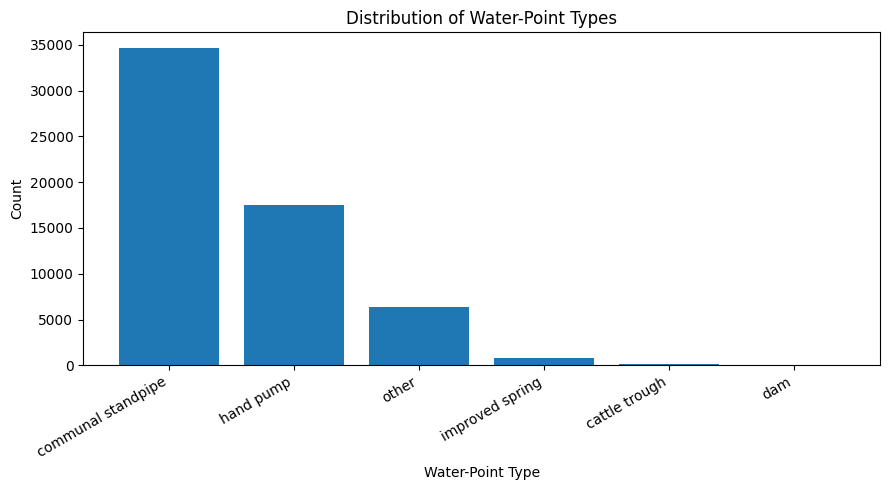

In [88]:
counts = df["waterpoint_type_group"].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(counts.index, counts.values)

plt.title("Distribution of Water-Point Types")
plt.xlabel("Water-Point Type")
plt.ylabel("Count")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

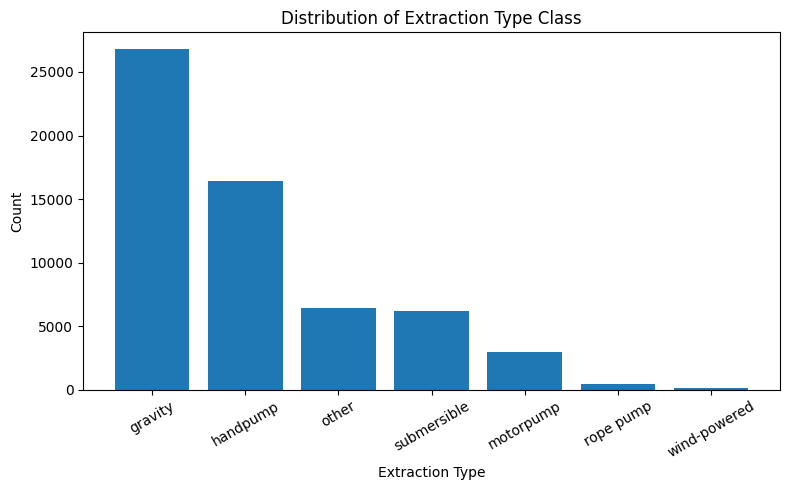

In [89]:
counts = df["extraction_type_class"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(counts.index, counts.values)

plt.title("Distribution of Extraction Type Class")
plt.xlabel("Extraction Type")
plt.ylabel("Count")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [90]:
def plot_categorical_distribution(df, column, top_n=None):
    counts = df[column].value_counts(dropna=False)

    if top_n is not None:
        counts = counts.head(top_n)

    percentages = (counts / len(df)) * 100

    plt.figure(figsize=(9, 5))

    bars = plt.bar(
        counts.index.astype(str),
        counts.values
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Count")

    plt.xticks(rotation=30, ha="right")

    # Add percentage labels above bars
    for bar, pct in zip(bars, percentages):
        height = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{pct:.1f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

    plt.tight_layout()
    plt.show()

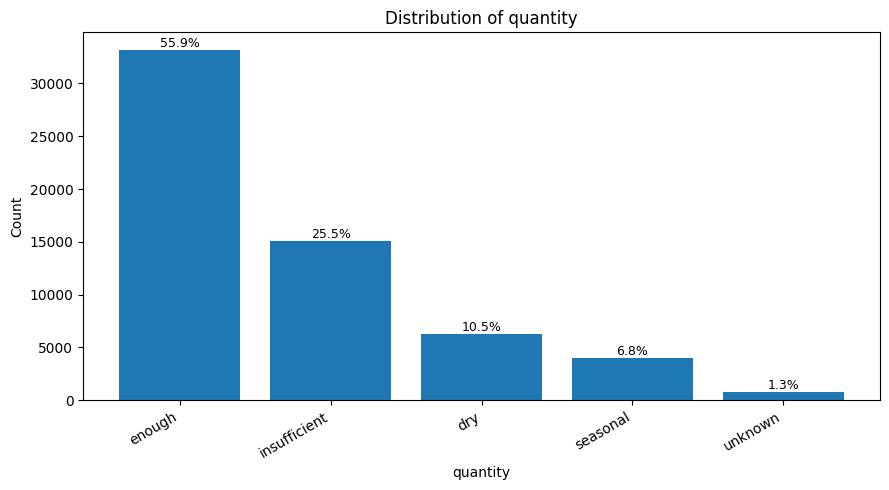

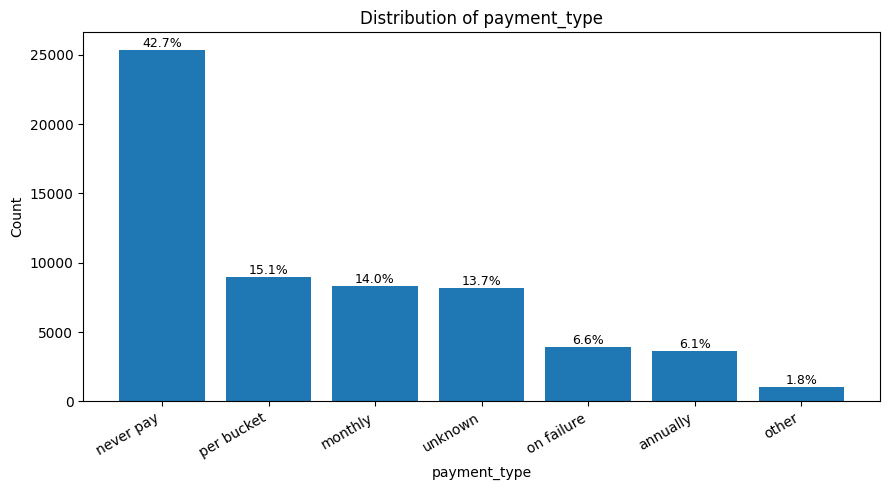

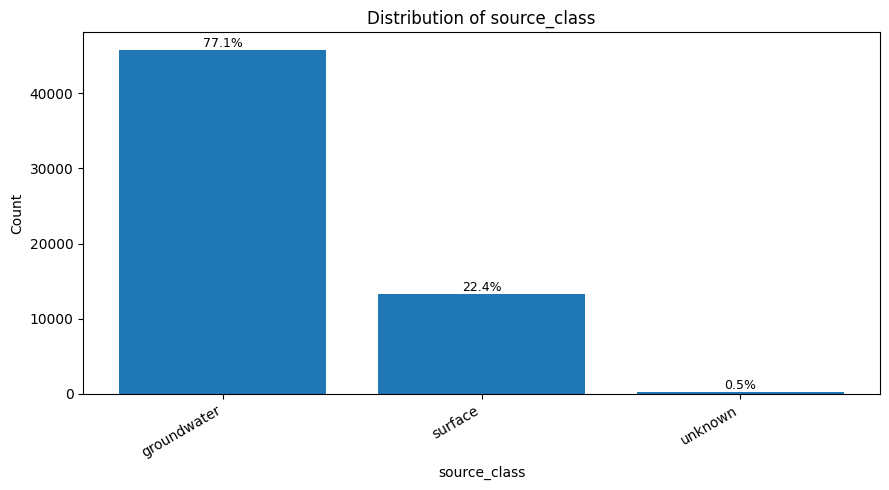

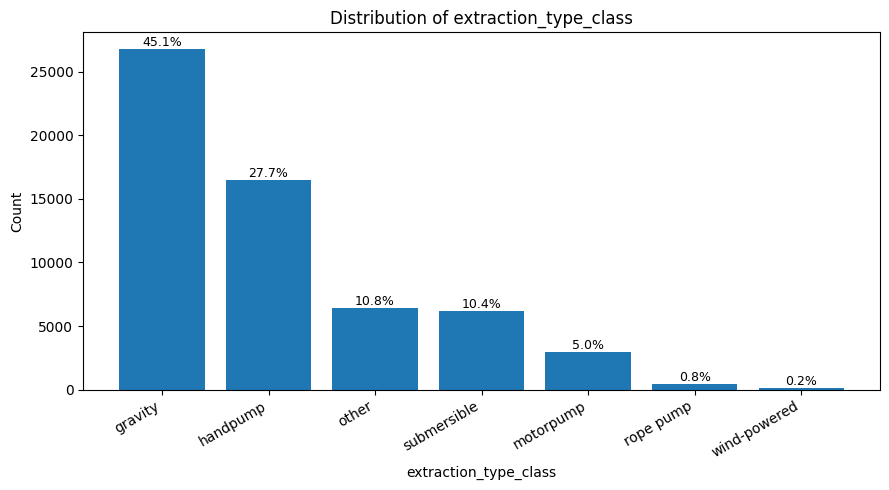

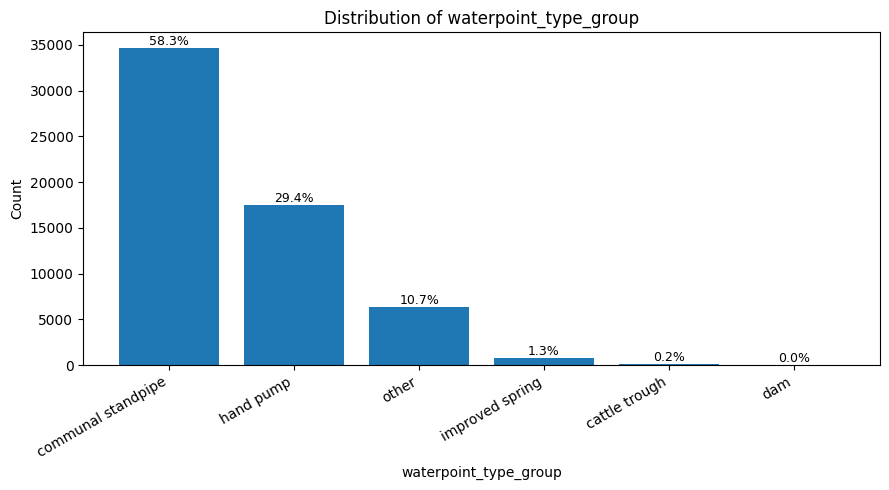

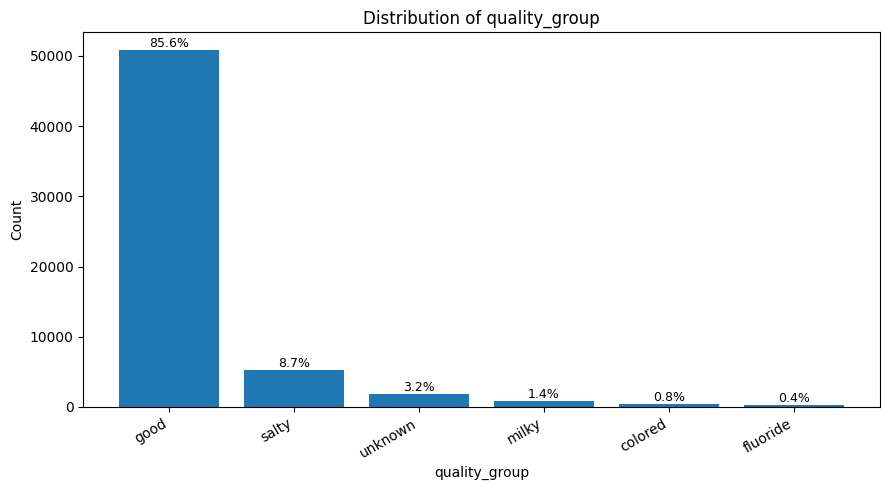

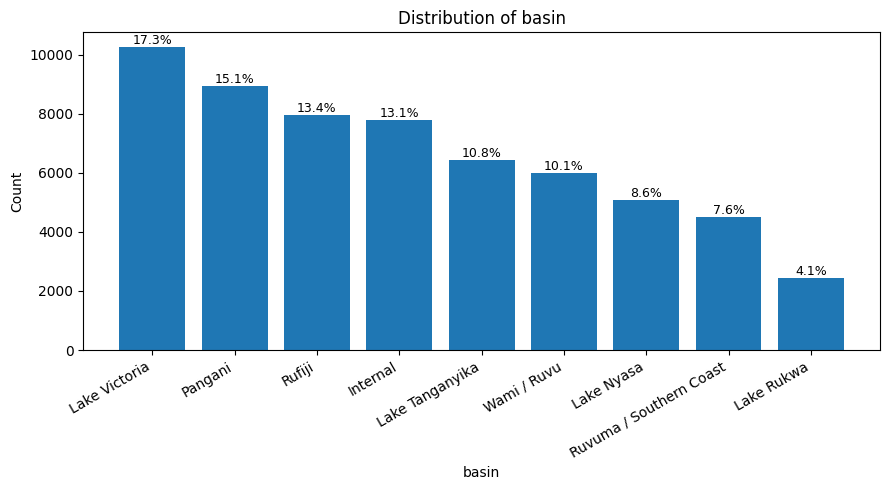

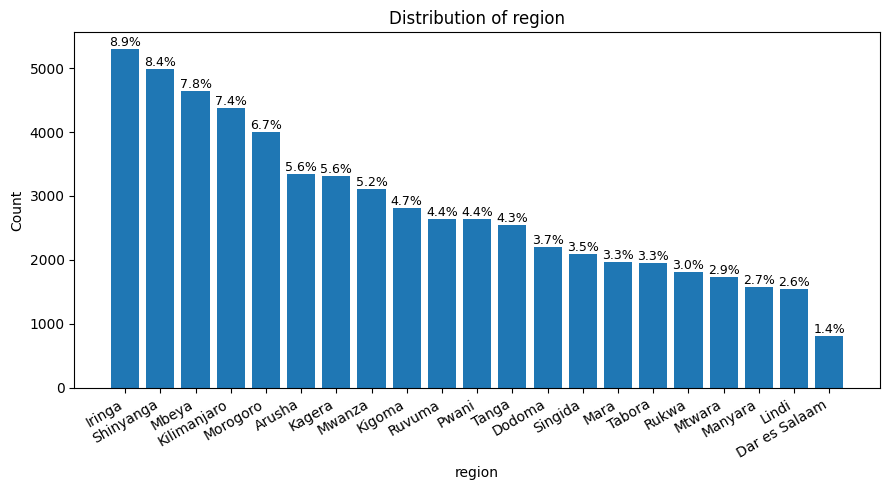

In [91]:
plot_categorical_distribution(df, "quantity")
plot_categorical_distribution(df, "payment_type")
plot_categorical_distribution(df, "source_class")
plot_categorical_distribution(df, "extraction_type_class")
plot_categorical_distribution(df, "waterpoint_type_group")
plot_categorical_distribution(df, "quality_group")
plot_categorical_distribution(df, "basin")
plot_categorical_distribution(df, "region", top_n=21)

### Key Observations

Several categorical variables show strongly uneven category distributions.

Water quantity is primarily recorded as `enough`, followed by `insufficient`, while smaller proportions are classified as `dry`, `seasonal`, or `unknown`.

Communal standpipes and hand pumps represent the dominant water-point types.

Gravity-based systems and hand pumps account for a large proportion of extraction technologies.

The most common payment arrangement is `never pay`, while several other payment categories and an `unknown` category are also present.

Groundwater represents the dominant water-source class.

Water quality is heavily concentrated in the `good` category.

Regional observations are distributed across multiple areas, providing useful geographic variation within the dataset.

These uneven category frequencies should be considered when selecting categorical encoding and feature-engineering strategies during preprocessing.

## 8. Relationship Between Predictor Variables and Operational Status

The next stage investigates whether predictor variables exhibit meaningful differences across the three operational-status classes.

The objective is not to establish causation, but to identify associations that may contain useful predictive information.

Categorical variables are compared using class proportions within each category, while selected numerical and derived variables are compared across target classes.

In [92]:
def plot_category_vs_target(df, feature, target="status_group"):
    table = pd.crosstab(
        df[feature],
        df[target],
        normalize="index"
    ) * 100

    table.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 6)
    )

    plt.title(f"{feature} vs {target}")
    plt.xlabel(feature)
    plt.ylabel("Percentage within category (%)")
    plt.xticks(rotation=35, ha="right")
    plt.legend(title="Status")
    plt.tight_layout()
    plt.show()

    return table.round(2)

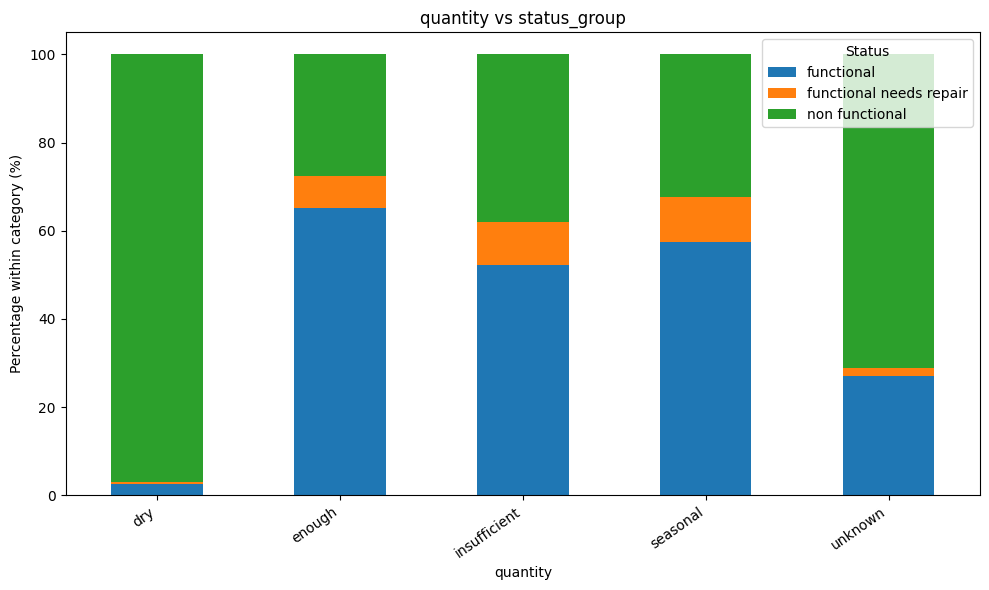

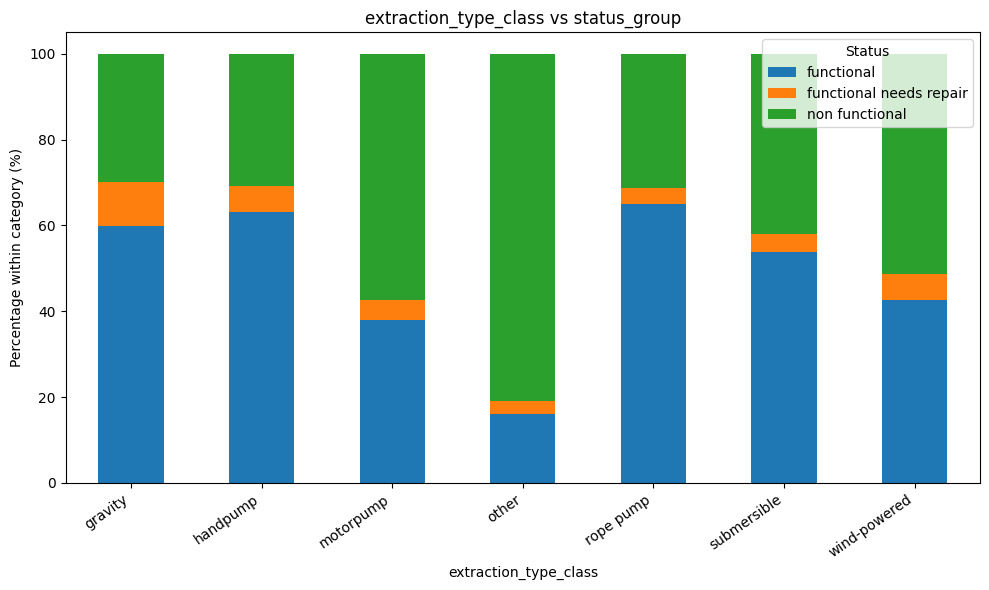

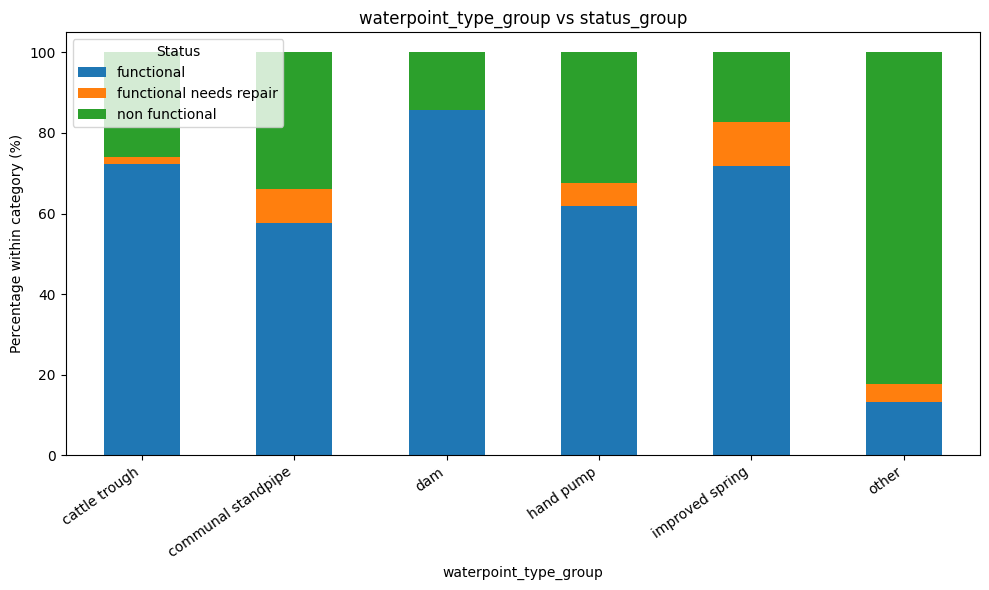

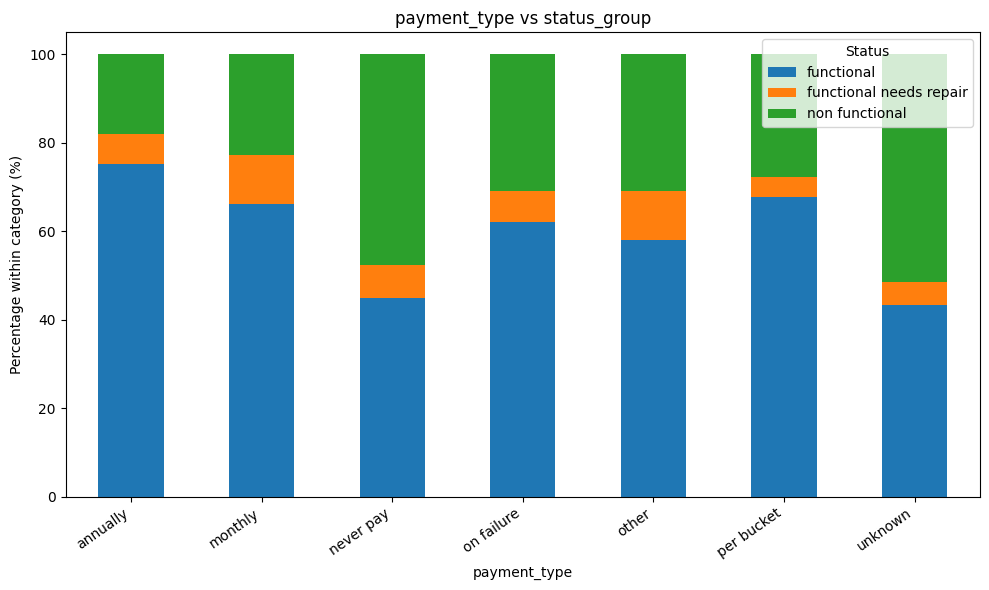

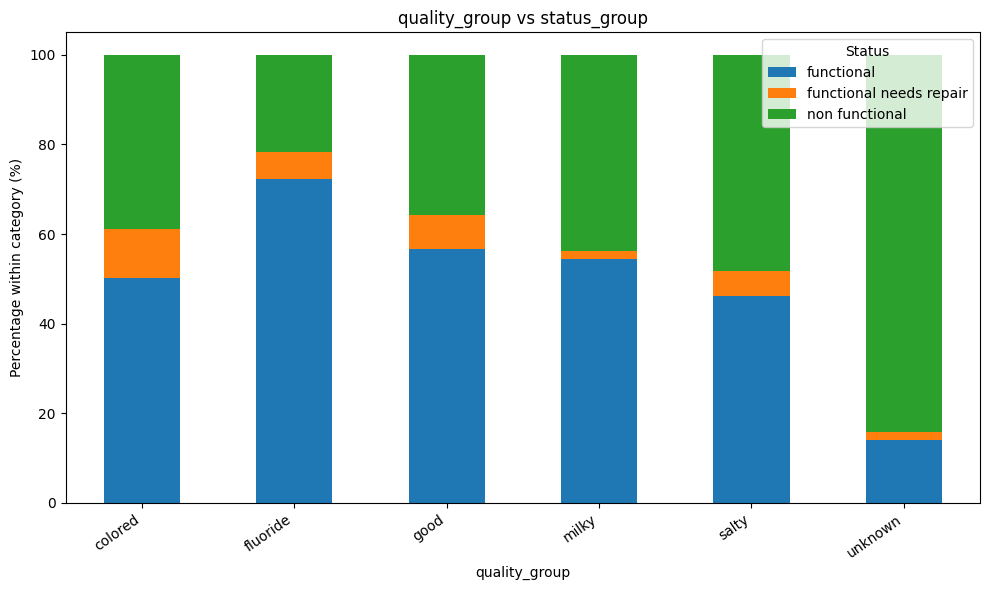

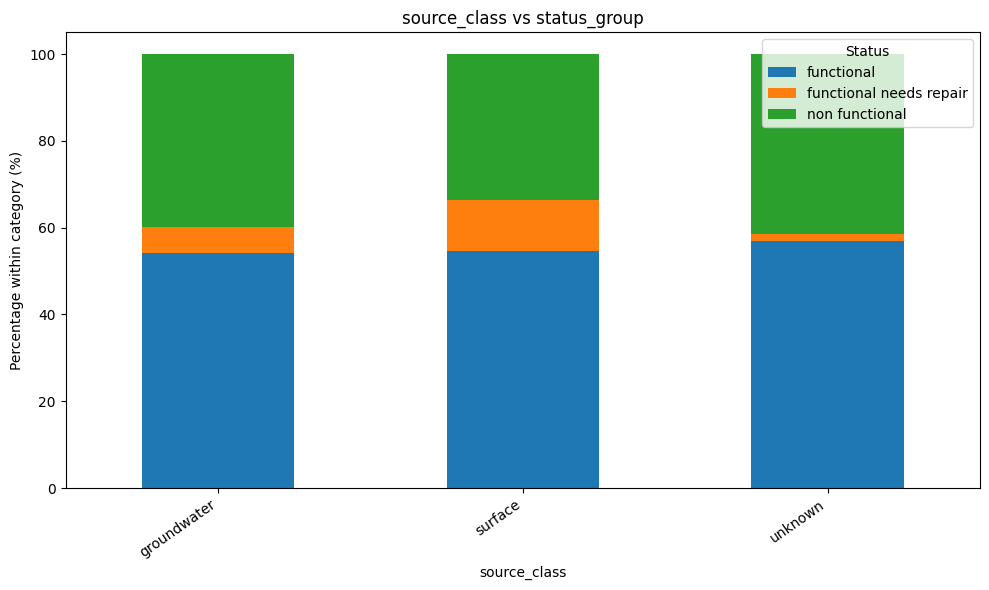

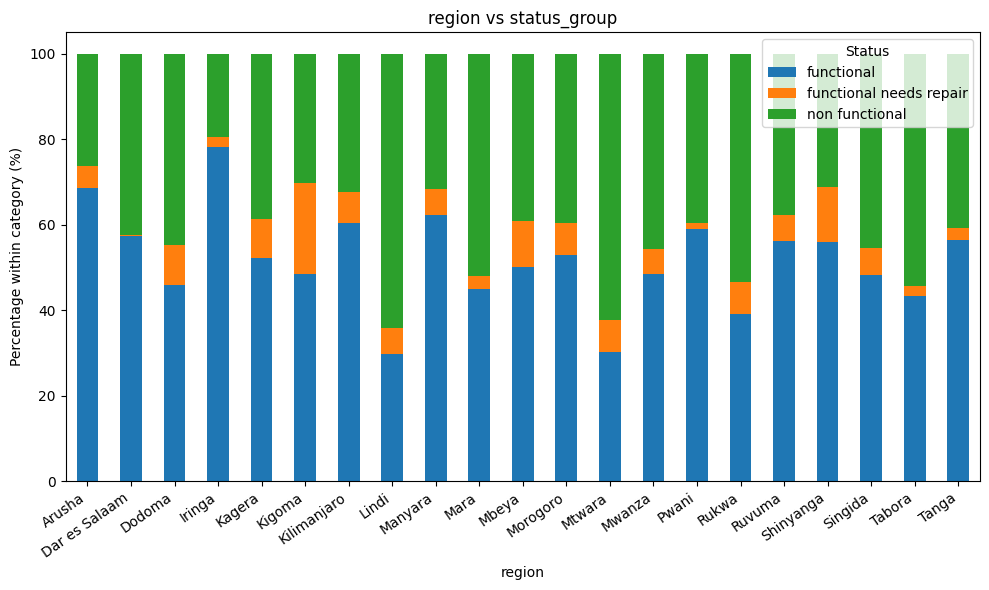

status_group,functional,functional needs repair,non functional
region,,,
Arusha,68.48,5.22,26.30
Dar es Salaam,57.27,0.37,42.36
Dodoma,45.84,9.50,44.66
Iringa,78.22,2.32,19.46
Kagera,52.08,9.17,38.75
Kigoma,48.40,21.41,30.18
Kilimanjaro,60.29,7.35,32.36
Lindi,29.75,6.02,64.23
Manyara,62.35,6.06,31.59


In [93]:
plot_category_vs_target(df, "quantity")
plot_category_vs_target(df, "extraction_type_class")
plot_category_vs_target(df, "waterpoint_type_group")
plot_category_vs_target(df, "payment_type")
plot_category_vs_target(df, "quality_group")
plot_category_vs_target(df, "source_class")
plot_category_vs_target(df, "region")

Numerical features vs target

In [94]:
numeric_target_summary = (
    df.groupby("status_group")[
        [
            "amount_tsh",
            "gps_height",
            "population",
            "construction_year"
        ]
    ]
    .agg(["mean", "median"])
)

numeric_target_summary

amount_tsh         gps_height         population  \
                               mean median        mean median        mean   
status_group                                                                
functional               461.798235    0.0  740.131188  550.0  187.553303   
functional needs repair  267.071577    0.0  627.607135  385.0  175.102154   
non functional           123.481230    0.0  574.464774  293.0  170.016430   

                               construction_year          
                        median              mean  median  
status_group                                              
functional                40.0       1345.567718  1995.0  
functional needs repair   25.0       1168.406764  1978.0  
non functional             1.0       1262.183491  1980.0

In [95]:
valid_year_data = df[df["construction_year"] > 0]

valid_year_data.groupby("status_group")[
    "construction_year"
].agg(["mean", "median", "count"])

,mean,median,count
status_group,,,
functional,1999.938675,2003.0,21704
functional needs repair,1995.257911,1998.0,2528
non functional,1992.397538,1994.0,14459


In [96]:
recorded_date_eda = pd.to_datetime(
    df["date_recorded"],
    errors="coerce"
)

waterpoint_age_eda = (
    recorded_date_eda.dt.year -
    df["construction_year"].replace(0, np.nan)
)

age_analysis = pd.DataFrame({
    "waterpoint_age": waterpoint_age_eda,
    "status_group": df["status_group"]
})

age_analysis.groupby("status_group")[
    "waterpoint_age"
].agg(["mean", "median"])

,mean,median
status_group,,
functional,12.169969,9.0
functional needs repair,17.200554,14.0
non functional,19.815271,18.0


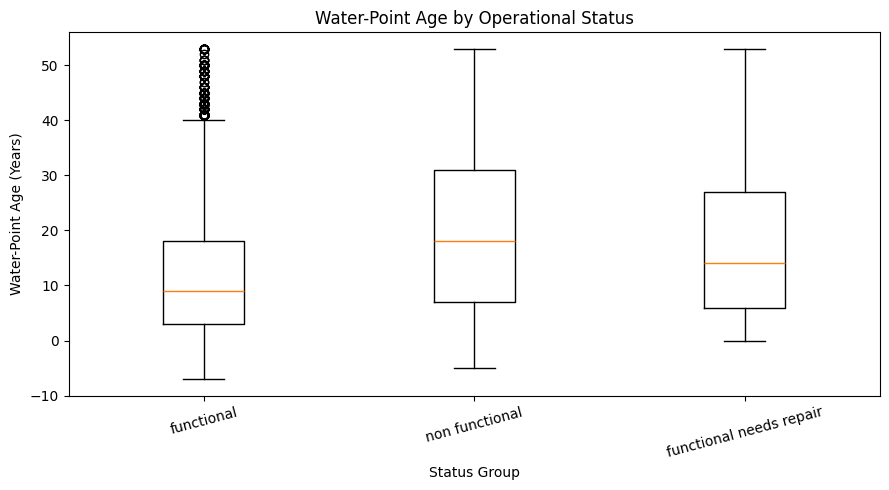

In [97]:
statuses = df["status_group"].unique()

age_groups = [
    age_analysis.loc[
        age_analysis["status_group"] == status,
        "waterpoint_age"
    ].dropna()
    for status in statuses
]

plt.figure(figsize=(9, 5))

plt.boxplot(
    age_groups,
    tick_labels=statuses
)

plt.title("Water-Point Age by Operational Status")
plt.xlabel("Status Group")
plt.ylabel("Water-Point Age (Years)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### Key Observations

Several variables show meaningful differences across operational-status classes.

Water quantity demonstrates a particularly strong relationship with the target. Water points recorded as `dry` are overwhelmingly represented in the non-functional class, while water points with sufficient water have substantially higher functional proportions.

Extraction technology and water-point type also show clear differences in operational-status distributions.

Payment arrangements, water-quality categories, and geographic region demonstrate additional variation across the three classes.

Construction-year analysis suggests that older water points are more frequently associated with non-functional status.

A temporary EDA feature representing water-point age was derived using the recorded year and valid construction year. The median age was lower among functional water points and higher among non-functional water points, suggesting that infrastructure age may contain useful predictive information.

These relationships indicate that the dataset contains meaningful predictive signal.

However, extremely strong relationships, particularly between water quantity and operational status, should be reviewed carefully for possible target leakage or conceptual overlap before model development.

## 9. Feature Redundancy and Association Analysis

This section investigates whether multiple predictor variables contain duplicated, strongly overlapping, or hierarchically related information.

Redundant features can unnecessarily increase model complexity and may duplicate the influence of the same underlying characteristic.

The analysis focuses on:

- exact duplicate features,
- one-to-one categorical mappings,
- grouped/hierarchical categorical features,
- and associations among numerical variables.

No features are removed at this stage. The findings will instead guide feature-selection decisions during preprocessing.

9.1 Check known related feature families

In [98]:
def check_feature_mapping(df, feature_a, feature_b):
    a_to_b = (
        df.groupby(feature_a, dropna=False)[feature_b]
        .nunique(dropna=False)
    )

    b_to_a = (
        df.groupby(feature_b, dropna=False)[feature_a]
        .nunique(dropna=False)
    )

    print(f"{feature_a} -> {feature_b}")
    print("Maximum number of B categories for one A category:", a_to_b.max())

    print(f"\n{feature_b} -> {feature_a}")
    print("Maximum number of A categories for one B category:", b_to_a.max())

    print(
        "\nUnique category pairs:",
        df[[feature_a, feature_b]]
        .drop_duplicates()
        .shape[0]
    )

In [99]:
check_feature_mapping(df, "quantity", "quantity_group")

quantity -> quantity_group
Maximum number of B categories for one A category: 1

quantity_group -> quantity
Maximum number of A categories for one B category: 1

Unique category pairs: 5


In [100]:
check_feature_mapping(df, "payment", "payment_type")

payment -> payment_type
Maximum number of B categories for one A category: 1

payment_type -> payment
Maximum number of A categories for one B category: 1

Unique category pairs: 7


In [101]:
check_feature_mapping(df, "management", "management_group")

management -> management_group
Maximum number of B categories for one A category: 1

management_group -> management
Maximum number of A categories for one B category: 4

Unique category pairs: 12


In [102]:
check_feature_mapping(df, "water_quality", "quality_group")

water_quality -> quality_group
Maximum number of B categories for one A category: 1

quality_group -> water_quality
Maximum number of A categories for one B category: 2

Unique category pairs: 8


In [103]:
check_feature_mapping(df, "source", "source_type")

source -> source_type
Maximum number of B categories for one A category: 1

source_type -> source
Maximum number of A categories for one B category: 2

Unique category pairs: 10


In [104]:
check_feature_mapping(df, "source_type", "source_class")

source_type -> source_class
Maximum number of B categories for one A category: 1

source_class -> source_type
Maximum number of A categories for one B category: 3

Unique category pairs: 7


In [105]:
check_feature_mapping(df, "waterpoint_type", "waterpoint_type_group")

waterpoint_type -> waterpoint_type_group
Maximum number of B categories for one A category: 1

waterpoint_type_group -> waterpoint_type
Maximum number of A categories for one B category: 2

Unique category pairs: 7


In [106]:
check_feature_mapping(df, "extraction_type", "extraction_type_group")

extraction_type -> extraction_type_group
Maximum number of B categories for one A category: 1

extraction_type_group -> extraction_type
Maximum number of A categories for one B category: 4

Unique category pairs: 18


In [107]:
check_feature_mapping(df, "extraction_type_group", "extraction_type_class")

extraction_type_group -> extraction_type_class
Maximum number of B categories for one A category: 1

extraction_type_class -> extraction_type_group
Maximum number of A categories for one B category: 6

Unique category pairs: 13


9.2 Important findings

In [108]:
(df["quantity"] == df["quantity_group"]).mean()

np.float64(1.0)

quantity and quantity_group

These are exactly identical.

Every row contains the same category in both columns.
So this is genuine duplication.

9.3 payment and payment_type

In [109]:
df[
    ["payment", "payment_type"]
].drop_duplicates().sort_values("payment")

,payment,payment_type
1,never pay,never pay
12,other,other
0,pay annually,annually
13,pay monthly,monthly
2,pay per bucket,per bucket
11,pay when scheme fails,on failure
7,unknown,unknown


In [110]:
related_features = [
    ("quantity", "quantity_group"),
    ("payment", "payment_type"),
    ("management", "management_group"),
    ("water_quality", "quality_group"),
    ("source", "source_type"),
    ("source_type", "source_class"),
    ("waterpoint_type", "waterpoint_type_group"),
    ("extraction_type", "extraction_type_group"),
    ("extraction_type_group", "extraction_type_class")
]

redundancy_summary = []

for feature_a, feature_b in related_features:

    a_to_b = (
        df.groupby(feature_a, dropna=False)[feature_b]
        .nunique(dropna=False)
    )

    b_to_a = (
        df.groupby(feature_b, dropna=False)[feature_a]
        .nunique(dropna=False)
    )

    redundancy_summary.append({
        "feature_a": feature_a,
        "feature_b": feature_b,
        "A_to_B_max": a_to_b.max(),
        "B_to_A_max": b_to_a.max(),
        "unique_A": df[feature_a].nunique(dropna=False),
        "unique_B": df[feature_b].nunique(dropna=False)
    })

redundancy_summary = pd.DataFrame(redundancy_summary)

redundancy_summary

,feature_a,feature_b,A_to_B_max,B_to_A_max,unique_A,unique_B
0,quantity,quantity_group,1,1,5,5
1,payment,payment_type,1,1,7,7
2,management,management_group,1,4,12,5
3,water_quality,quality_group,1,2,8,6
4,source,source_type,1,2,10,7
5,source_type,source_class,1,3,7,3
6,waterpoint_type,waterpoint_type_group,1,2,7,6
7,extraction_type,extraction_type_group,1,4,18,13
8,extraction_type_group,extraction_type_class,1,6,13,7


Observation

payment and payment_type have a one-to-one categorical relationship, indicating that both features describe the same underlying payment arrangement using different labels.

9.4 Hierarchical Categorical Features

Several categorical variables represent the same real-world concept at different levels of detail. These are not necessarily exact duplicates, but they form hierarchical groupings. Understanding these relationships is important because keeping every level may introduce redundant information into the modelling stage.

#### Observed Hierarchical Relationships

**Management**

`management` contains more detailed management categories, while `management_group` combines them into broader groups.

Examples:

- `vwc` → `user-group`
- `wug` → `user-group`
- `wua` → `user-group`
- `water board` → `user-group`
- `company` → `commercial`
- `private operator` → `commercial`
- `water authority` → `commercial`

Therefore, `management_group` is a broader representation of `management`.

**Water Source**

The source variables form a three-level hierarchy:

`source` → `source_type` → `source_class`

Examples:

- `machine dbh` / `hand dtw` → `borehole` → `groundwater`
- `river` / `lake` → `river/lake` → `surface`

This means the same underlying source information is represented at different levels of detail.

**Extraction Technology**

The extraction variables also form a hierarchy:

`extraction_type` → `extraction_type_group` → `extraction_type_class`

For example, several detailed hand-pump technologies such as:

- `afridev`
- `india mark ii`
- `india mark iii`
- `nira/tanira`
- `swn 80`

are grouped into the broader `handpump` category.

Therefore, these variables represent increasingly broader levels of extraction technology.

**Water-Point Type**

`waterpoint_type` contains more detailed water-point categories, while `waterpoint_type_group` combines related categories.

For example:

- `communal standpipe`
- `communal standpipe multiple`

are grouped under:

- `communal standpipe`

This suggests that the grouped variable may provide similar information with lower categorical complexity.

#### Interpretation

These hierarchical features indicate potential redundancy in the dataset. Some variables provide detailed information while others provide broader grouped versions of the same characteristic.

At this EDA stage, no variables are removed. During preprocessing and feature selection, the detailed and grouped representations should be compared to determine which level provides sufficient predictive information without unnecessarily increasing feature complexity.

### 9.5 Numerical Feature Association

Spearman correlation is used to examine relationships between numerical variables because several features are skewed and contain unusual or zero values.

The purpose is to identify strongly related numerical predictors that may contain overlapping information.

Correlation does not imply causation, and the results should be interpreted cautiously because some variables contain potentially missing values encoded as zero.

In [111]:
numeric_for_correlation = [
    "amount_tsh",
    "gps_height",
    "longitude",
    "latitude",
    "num_private",
    "population",
    "construction_year"
]

spearman_corr = df[numeric_for_correlation].corr(method="spearman")

spearman_corr.round(2)

,amount_tsh,gps_height,longitude,latitude,num_private,population,construction_year
amount_tsh,1.00,0.34,0.21,-0.26,0.03,0.34,0.41
gps_height,0.34,1.00,0.16,-0.09,0.04,0.55,0.61
longitude,0.21,0.16,1.00,-0.36,0.14,0.40,0.48
latitude,-0.26,-0.09,-0.36,1.00,-0.01,-0.14,-0.19
num_private,0.03,0.04,0.14,-0.01,1.00,0.03,0.05
population,0.34,0.55,0.40,-0.14,0.03,1.00,0.68
construction_year,0.41,0.61,0.48,-0.19,0.05,0.68,1.00


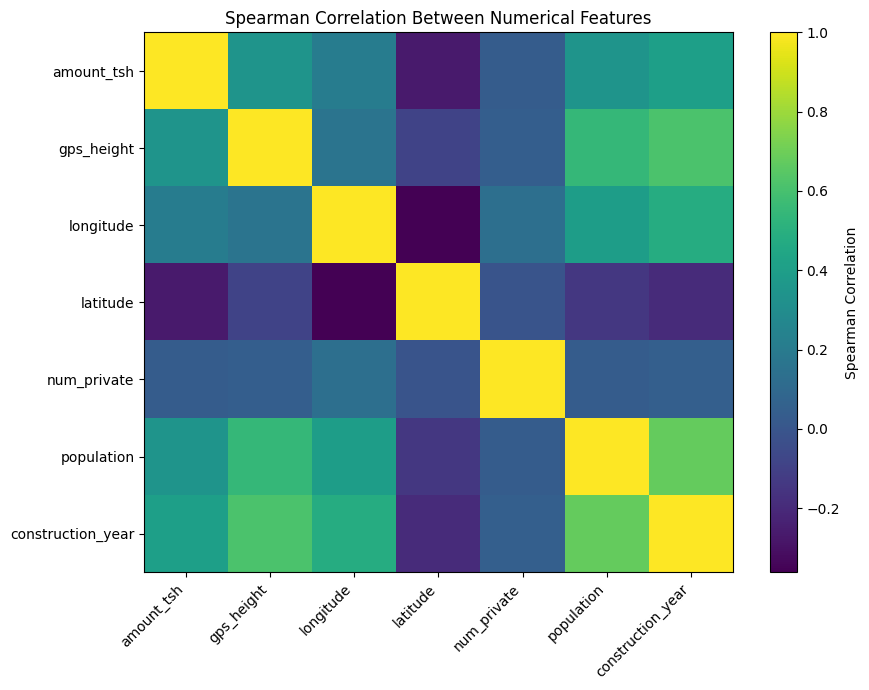

In [112]:
plt.figure(figsize=(9, 7))

plt.imshow(
    spearman_corr,
    aspect="auto"
)

plt.colorbar(label="Spearman Correlation")

plt.xticks(
    range(len(spearman_corr.columns)),
    spearman_corr.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(spearman_corr.index)),
    spearman_corr.index
)

plt.title("Spearman Correlation Between Numerical Features")

plt.tight_layout()
plt.show()

#### Interpretation

Some numerical variables show moderate associations with one another.

However, these correlations should be interpreted carefully because variables such as `construction_year`, `population`, and `gps_height` contain large numbers of zero values, some of which may represent unavailable or uncertain information.

Therefore, no numerical features are removed based only on the raw correlation matrix. Correlations will be reconsidered after appropriate preprocessing.

### 9.6 Relationship Between Region and Region Code

`region` and `region_code` both describe geographic information. Their relationship is examined to determine whether they are exact duplicates or provide different levels of geographic information.

In [113]:
region_mapping = pd.crosstab(
    df["region"],
    df["region_code"]
)

region_mapping

region_code,1,2,3,4,5,6,7,8,9,10,...,18,19,20,21,24,40,60,80,90,99
region,,,,,,,,,,,,,,,,,,,,,
Arusha,0,3024,0,0,0,0,0,0,0,0,...,0,0,0,0,326,0,0,0,0,0
Dar es Salaam,0,0,0,0,0,0,805,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Dodoma,2201,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Iringa,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Kagera,0,0,0,0,0,0,0,0,0,0,...,3316,0,0,0,0,0,0,0,0,0
Kigoma,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Kilimanjaro,0,0,4379,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Lindi,0,0,0,0,0,0,0,300,0,0,...,8,0,0,0,0,0,0,1238,0,0
Manyara,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1583,0,0,0,0,0,0


In [114]:
check_feature_mapping(
    df,
    "region",
    "region_code"
)

region -> region_code
Maximum number of B categories for one A category: 3

region_code -> region
Maximum number of A categories for one B category: 2

Unique category pairs: 32


#### Interpretation

`region` and `region_code` are related geographic variables, but they are not treated as exact duplicates.

Their usefulness will therefore be assessed later during preprocessing and feature selection rather than automatically removing one during EDA.

### Step 9 Summary

The redundancy analysis identified several important patterns:

- `quantity` and `quantity_group` contain duplicate information.
- `payment` and `payment_type` represent the same payment concept using different category labels.
- Several feature families form hierarchical relationships, including management, water quality, source, extraction technology, and water-point type.
- Some numerical features show moderate correlations, although these relationships may be influenced by zero or potentially missing values.
- `region` and `region_code` are related but are not treated as exact duplicates.

These findings indicate that the dataset contains multiple overlapping representations of the same underlying characteristics.

No variables are removed during this EDA stage. The findings will instead guide redundancy reduction and feature selection during preprocessing.

## 10. Geographic Exploratory Analysis

The dataset contains several geographic variables, including longitude, latitude, GPS height, region, basin, district, LGA, and ward.

This section investigates:

- the validity of geographic coordinates,
- the spatial distribution of recorded water points,
- whether operational-status classes show geographic patterns,
- and whether invalid or missing coordinate information requires later preprocessing.

The original dataset is not modified during this analysis.

### 10.1 Geographic Coordinate Quality

The longitude and latitude variables are examined to identify invalid or unusual coordinate values.

Previous numerical analysis identified observations with longitude equal to zero and latitude values extremely close to zero. These records are investigated to determine whether they are likely to represent unavailable geographic information.

In [115]:
geo_summary = df[
    ["longitude", "latitude", "gps_height"]
].describe().T

geo_summary

,count,mean,std,min,25%,50%,75%,max
longitude,59400.0,34.077427,6.567432,0.00000,33.090347,34.908743,37.178387,4.034519e+01
latitude,59400.0,-5.706033,2.946019,-11.64944,-8.540621,-5.021597,-3.326156,-2.000000e-08
gps_height,59400.0,668.297239,693.116350,-90.00000,0.000000,369.000000,1319.250000,2.770000e+03


### 10.1 Geographic Coordinate Quality

Longitude and latitude are examined to identify unusual or potentially invalid coordinate values.

Previous numerical analysis identified records where longitude is equal to zero and latitude is extremely close to zero. These observations are investigated because they may represent unavailable geographic information rather than valid locations.

In [116]:
invalid_coordinate_mask = (
    (df["longitude"] == 0) &
    (df["latitude"].abs() < 0.001)
)

invalid_count = invalid_coordinate_mask.sum()
invalid_percentage = invalid_coordinate_mask.mean() * 100

print("Likely invalid coordinate records:", invalid_count)
print(
    "Percentage of dataset:",
    round(invalid_percentage, 2),
    "%"
)

Likely invalid coordinate records: 1812
Percentage of dataset: 3.05 %


#### Observation

A group of observations contains longitude equal to zero together with latitude values extremely close to zero.

These coordinates are inconsistent with the main geographic range represented in the dataset and are therefore likely to indicate invalid or unavailable geographic information.

These records are not removed during EDA. Their treatment will be considered during the preprocessing stage.

### 10.2 Valid Coordinates for Geographic Visualization

To examine the spatial distribution more clearly, observations containing likely invalid coordinate values are temporarily excluded from the geographic visualizations.

This filtering is performed only for EDA purposes and does not modify or remove records from the original analytical dataset.

In [117]:
geo_eda = df.loc[
    ~invalid_coordinate_mask
].copy()

print("Original number of records:", len(df))
print(
    "Records used for geographic visualization:",
    len(geo_eda)
)

Original number of records: 59400
Records used for geographic visualization: 57588


### 10.3 Spatial Distribution of Water Points

The valid longitude and latitude values are plotted to examine the overall geographic distribution of water points.

The purpose of this analysis is to determine whether the coordinate variables contain meaningful spatial information and whether the observations form a coherent geographic pattern.

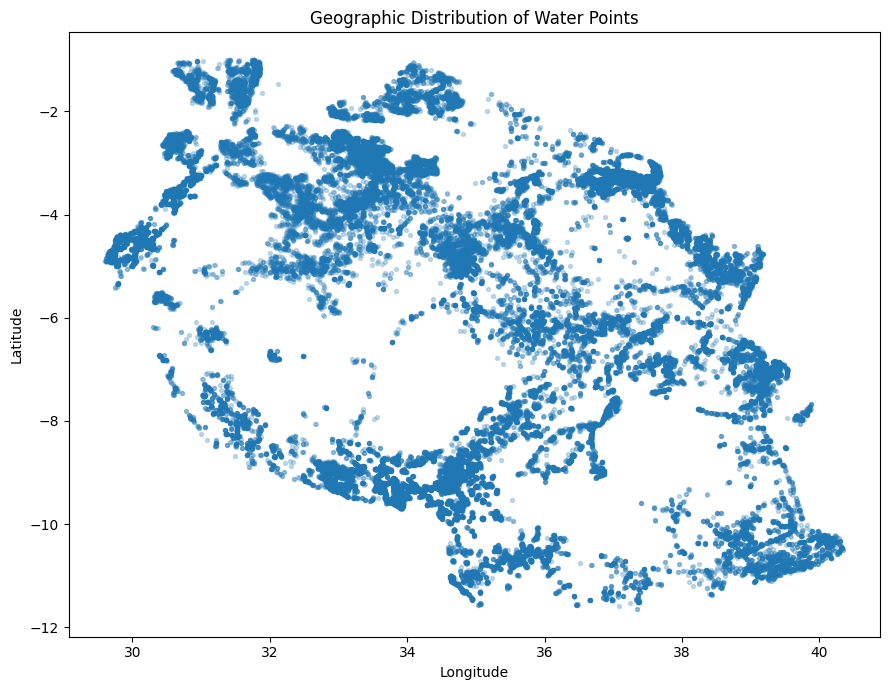

In [118]:
plt.figure(figsize=(9, 7))

plt.scatter(
    geo_eda["longitude"],
    geo_eda["latitude"],
    alpha=0.25,
    s=8
)

plt.title("Geographic Distribution of Water Points")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.show()

#### Observation

After excluding the likely invalid coordinate values for visualization, the remaining water points form a coherent geographic distribution.

This indicates that longitude and latitude contain meaningful spatial information and may provide useful predictive information during model development.

### 10.4 Geographic Distribution by Operational Status

The geographic distribution is examined separately for the three operational-status classes.

This analysis investigates whether functional, repair-needed, and non-functional water points exhibit visible geographic patterns or clustering.

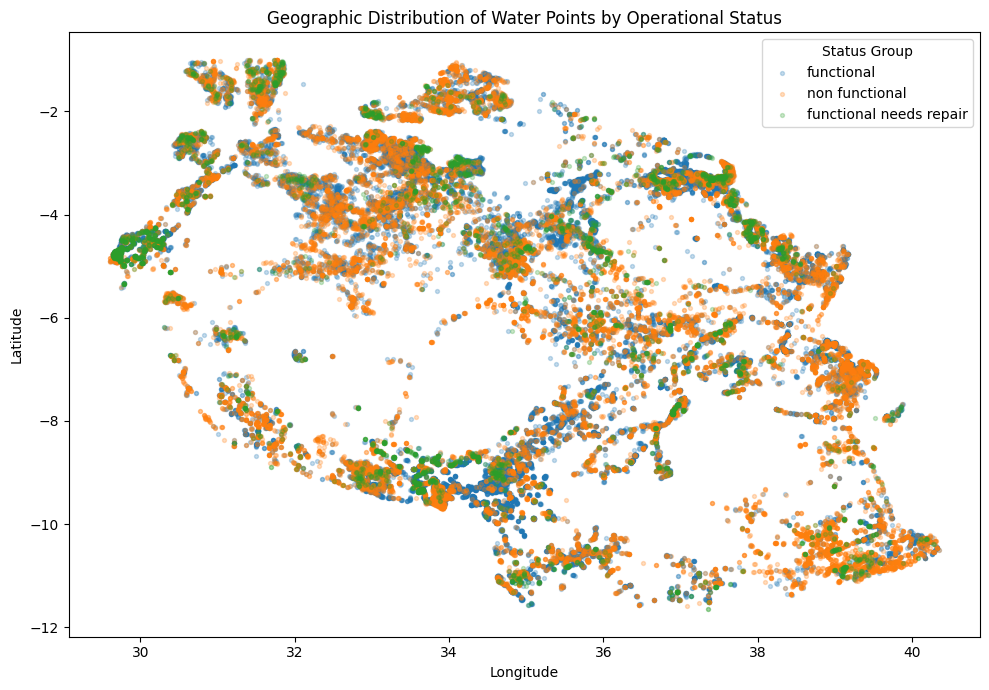

In [119]:
plt.figure(figsize=(10, 7))

for status in df["status_group"].unique():

    subset = geo_eda[
        geo_eda["status_group"] == status
    ]

    plt.scatter(
        subset["longitude"],
        subset["latitude"],
        s=8,
        alpha=0.25,
        label=status
    )

plt.title(
    "Geographic Distribution of Water Points by Operational Status"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend(title="Status Group")

plt.tight_layout()
plt.show()

#### Observation

All three operational-status classes are distributed across the study area rather than being restricted to a single geographic location.

However, the relative concentration of the classes appears to vary geographically.

These patterns may reflect differences in infrastructure, environmental conditions, management practices, water sources, or other regional characteristics.

The observed patterns represent associations and do not demonstrate that geographic location itself causes water-point failure.

### 10.5 Invalid Geographic Information by Target Class

The proportion of likely invalid coordinate records is compared across the operational-status classes.

This analysis helps determine whether unavailable geographic information occurs equally across the target classes or whether the missingness pattern differs by operational status.

In [120]:
invalid_geo_by_target = pd.crosstab(
    df["status_group"],
    invalid_coordinate_mask,
    normalize="index"
) * 100

invalid_geo_by_target.columns = [
    "Valid Coordinates",
    "Likely Invalid Coordinates"
]

invalid_geo_by_target.round(2)

,Valid Coordinates,Likely Invalid Coordinates
status_group,,
functional,97.30,2.70
functional needs repair,91.06,8.94
non functional,97.56,2.44


#### Observation

The proportion of likely invalid geographic coordinates can vary between operational-status classes.

This suggests that missing or invalid location information may not be distributed completely uniformly across the target variable.

However, this relationship should not be interpreted as causal. The finding mainly indicates that coordinate missingness should be handled carefully during preprocessing.

In [121]:
region_geo_summary = (
    df.groupby("region")
    .agg(
        total_waterpoints=("status_group", "size"),
        non_functional_rate=(
            "status_group",
            lambda x:
                (x == "non functional").mean() * 100
        )
    )
    .sort_values(
        "non_functional_rate",
        ascending=False
    )
)

region_geo_summary.round(2)

,total_waterpoints,non_functional_rate
region,,
Lindi,1546,64.23
Mtwara,1730,62.43
Tabora,1959,54.42
Rukwa,1808,53.43
Mara,1969,51.96
Mwanza,3102,45.68
Singida,2093,45.58
Dodoma,2201,44.66
Dar es Salaam,805,42.36


#### Observation

The percentage of non-functional water points differs across regions.

This suggests that geographic information may contain useful predictive signal.

However, regional differences may also reflect other characteristics such as infrastructure age, extraction technology, water source, management arrangements, population, and environmental conditions.

Therefore, region should be treated as an associated geographic predictor rather than as a direct cause of water-point condition.

### 10.7 GPS Height and Operational Status

GPS height represents the altitude of each water point.

Because a large number of observations contain a GPS height of zero, the relationship with operational status is examined using both the complete variable and the subset containing non-zero altitude values.

In [122]:
df.groupby(
    "status_group"
)["gps_height"].agg(
    ["mean", "median"]
).round(2)

,mean,median
status_group,,
functional,740.13,550.0
functional needs repair,627.61,385.0
non functional,574.46,293.0


In [123]:
gps_nonzero = df[
    df["gps_height"] != 0
]

gps_nonzero.groupby(
    "status_group"
)["gps_height"].agg(
    ["mean", "median", "count"]
).round(2)

,mean,median,count
status_group,,,
functional,1095.73,1249.0,21790
functional needs repair,1060.84,1159.5,2554
non functional,896.95,997.0,14618


#### Observation

GPS height shows some variation across operational-status classes.

However, interpretation should remain cautious because a substantial number of observations contain zero altitude values, and it is uncertain whether every zero represents a genuine sea-level location or unavailable measurement.

Therefore, GPS height requires further consideration during preprocessing before its relationship with the target can be interpreted more confidently.

### Step 10 Summary

The geographic exploratory analysis identified several important findings:

- Longitude and latitude contain meaningful spatial information for most observations.
- A small proportion of records contain longitude equal to zero together with latitude values close to zero, indicating likely invalid or unavailable coordinate information.
- After temporarily excluding these records for visualization, the remaining water points form a coherent geographic distribution.
- Functional, non-functional, and repair-needed water points occur throughout the study area.
- Operational-status proportions vary across geographic regions.
- Geographic variables may therefore provide useful predictive information.
- Geographic differences may also represent underlying differences in infrastructure, management, water sources, environmental conditions, and water-point age.
- GPS height requires careful interpretation because of its large number of zero values.

No geographic records were permanently removed during this EDA stage. These findings will guide geographic-data treatment during preprocessing.

## 11. Data Leakage Investigation

Data leakage occurs when information that would not legitimately be available at prediction time is used during model training, causing unrealistically high model performance.

This section investigates several potential leakage risks:

- direct target information within predictor variables,
- features that may act as proxies for the target,
- identifier-like features that may encourage memorization,
- temporal and deployment-time availability of features,
- and leakage that could occur during preprocessing, resampling, feature selection, or model evaluation.

No variables are removed during this EDA stage. Potential leakage risks are documented so that they can be addressed during preprocessing and modelling.

### 11.1 Direct Target Leakage

The predictor variables are inspected to determine whether any feature directly contains or duplicates the target variable `status_group`.

A predictor that directly encodes the target would result in severe data leakage and must not be used for model training.

In [124]:
target = "status_group"

target_related_columns = [
    col for col in df.columns
    if (
        "status" in col.lower() or
        "functional" in col.lower()
    )
]

print("Columns with target-related names:")
print(target_related_columns)

Columns with target-related names:
['status_group']


In [125]:
predictor_columns = [
    col for col in df.columns
    if col != target
]

exact_target_duplicates = []

for col in predictor_columns:

    if df[col].astype(str).equals(
        df[target].astype(str)
    ):
        exact_target_duplicates.append(col)

print(
    "Predictor columns identical to target:",
    exact_target_duplicates
)

Predictor columns identical to target: []


#### Observation

No predictor variable directly duplicates the target variable `status_group`, and no additional target-like status variable was identified.

Therefore, no obvious direct target leakage is present in the dataset.

However, direct duplication is only one form of leakage. Features that describe the current condition of a water point may still act as strong proxies for the target and therefore require further investigation.

### 11.2 Potential Target Proxy: Water Quantity

Previous feature-target analysis identified a very strong relationship between `quantity` and `status_group`.

In particular, water points recorded as `dry` are overwhelmingly classified as non-functional.

A strong relationship does not automatically indicate data leakage. However, because `quantity` describes the current availability of water, it may represent information closely related to how operational status was determined.

Therefore, its availability at prediction time must be considered carefully.

In [126]:
quantity_target_table = pd.crosstab(
    df["quantity"],
    df["status_group"],
    normalize="index"
) * 100

quantity_target_table.round(2)

status_group,functional,functional needs repair,non functional
quantity,,,
dry,2.51,0.59,96.89
enough,65.23,7.23,27.54
insufficient,52.32,9.58,38.09
seasonal,57.41,10.27,32.32
unknown,27.00,1.77,71.23


#### Observation

`quantity` shows a particularly strong association with operational status. Approximately 97% of water points recorded as `dry` belong to the non-functional class.

This does not prove that `quantity` is target leakage. The important question is whether water quantity would genuinely be known when the prediction system is used.

If determining that a water point is `dry` requires physically inspecting the water point at the same time that its operational status is being assessed, the feature may provide information that is too close to the target and reduce the practical usefulness of the prediction system.

Therefore, `quantity` and its duplicate `quantity_group` are treated as potential target-proxy features. Their inclusion should be tested carefully during modelling, potentially by comparing model performance with and without this information.

### 11.3 Identifier-Like Features and Memorization Risk

Several categorical variables contain very large numbers of unique values.

Although these variables do not directly contain the target, extremely specific identifiers may allow a model to memorize individual water points or locations rather than learn patterns that generalize to unseen observations.

Their uniqueness is therefore reviewed as a model-generalization risk.

In [127]:
identifier_like_features = [
    "wpt_name",
    "subvillage",
    "scheme_name",
    "ward",
    "installer",
    "funder"
]

identifier_risk = []

for col in identifier_like_features:

    unique_count = df[col].nunique(
        dropna=True
    )

    identifier_risk.append({
        "feature": col,
        "unique_values": unique_count,
        "unique_ratio_%":
            round(
                unique_count / len(df) * 100,
                2
            )
    })

identifier_risk = pd.DataFrame(
    identifier_risk
).sort_values(
    "unique_ratio_%",
    ascending=False
)

identifier_risk

,feature,unique_values,unique_ratio_%
0,wpt_name,37399,62.96
1,subvillage,19287,32.47
2,scheme_name,2695,4.54
4,installer,2145,3.61
3,ward,2092,3.52
5,funder,1896,3.19


#### Observation

Variables such as `wpt_name` and `subvillage` have extremely high cardinality and may behave partly like identifiers.

These features are not considered direct target leakage. However, using them without appropriate treatment may encourage memorization of specific locations and result in overly optimistic model performance that does not generalize well to unseen water points.

These variables will therefore require careful feature-selection or encoding decisions during preprocessing.

### 11.4 Target Definition and Temporal Leakage Consideration

The target `status_group` represents the observed operational condition of a water point at the time represented by the dataset.

The dataset does not contain future failure events or a time-to-failure target.

Therefore, the project should be framed as predicting water-point operational status rather than forecasting whether a currently functional water point will fail in the future.

Describing the task as future failure prediction would not be supported by the available target data.

### 11.5 Leakage Through Preprocessing

Data leakage can also occur even when the original predictors are valid.

If preprocessing operations are fitted using the entire dataset before separating training and testing data, information from the test data can indirectly influence the trained model.

Potential sources include:

- missing-value imputation,
- scaling and normalization,
- categorical encoding,
- feature selection,
- rare-category grouping,
- target encoding,
- and dimensionality reduction.

To prevent this, the data will be separated into training and testing sets before fitting data-dependent preprocessing operations. Preprocessing parameters will be learned using training data only and then applied to the test data.

### 11.6 Class-Imbalance Handling and Leakage Prevention

The target variable contains a minority class (`functional needs repair`).

If techniques such as oversampling or SMOTE are later used to address class imbalance, they must only be applied to the training data.

Applying oversampling before the train-test split could create synthetic or duplicated observations that appear in both training and testing information, resulting in overly optimistic evaluation results.

The test set will retain the original class distribution and will not be artificially balanced.

### 11.7 Validation and Model-Selection Leakage

The final test dataset should represent unseen data and should not influence model selection or hyperparameter tuning.

Therefore:

- model comparison and hyperparameter optimization will be performed using training data and cross-validation,
- the test set will not be repeatedly used to select models,
- and the final test set will be used only after the modelling decisions have been finalized.

This prevents information from the test set indirectly influencing the selected model.

### 11.8 Target-Based Encoding Risk

High-cardinality categorical variables may potentially require encoding strategies beyond conventional one-hot encoding.

If target-based encoding is considered, target statistics must never be calculated using the complete dataset.

Target encoding would need to be calculated using training data only and, where appropriate, within cross-validation folds to prevent information from validation or test observations leaking into the encoded features.

### 11.9 Data Leakage Risk Summary

The identified leakage and generalization risks are summarized below together with their planned prevention strategies.

In [128]:
leakage_audit = pd.DataFrame({
    "Risk": [
        "Direct target duplication",
        "Current-state target proxy",
        "Identifier/location memorization",
        "Unsupported future prediction",
        "Preprocessing before data split",
        "Oversampling before data split",
        "Repeated test-set model selection",
        "Target encoding using full dataset"
    ],

    "Relevant Features / Process": [
        "status_group",
        "quantity / quantity_group",
        "wpt_name, subvillage, scheme_name, ward",
        "status_group target definition",
        "Imputation, scaling, encoding, feature selection",
        "SMOTE / oversampling",
        "Hyperparameter tuning and model comparison",
        "High-cardinality categorical encoding"
    ],

    "Risk Level": [
        "No direct leakage identified",
        "Potential",
        "Generalization risk",
        "Conceptual risk",
        "High if performed incorrectly",
        "High if performed incorrectly",
        "High if performed incorrectly",
        "High if performed incorrectly"
    ],

    "Planned Prevention": [
        "Exclude target from predictors",
        "Verify availability at prediction time and test models with/without feature",
        "Remove, group, or carefully encode identifier-like features",
        "Predict operational status, not future failure",
        "Split data before fitting preprocessing transformations",
        "Apply resampling only to training data",
        "Use cross-validation for model selection and reserve test set",
        "Fit target encoding using training folds only"
    ]
})

leakage_audit

,Risk,Relevant Features / Process,Risk Level,Planned Prevention
0,Direct target duplication,status_group,No direct leakage identified,Exclude target from predictors
1,Current-state target proxy,quantity / quantity_group,Potential,Verify availability at prediction time and tes...
2,Identifier/location memorization,"wpt_name, subvillage, scheme_name, ward",Generalization risk,"Remove, group, or carefully encode identifier-..."
3,Unsupported future prediction,status_group target definition,Conceptual risk,"Predict operational status, not future failure"
4,Preprocessing before data split,"Imputation, scaling, encoding, feature selection",High if performed incorrectly,Split data before fitting preprocessing transf...
5,Oversampling before data split,SMOTE / oversampling,High if performed incorrectly,Apply resampling only to training data
6,Repeated test-set model selection,Hyperparameter tuning and model comparison,High if performed incorrectly,Use cross-validation for model selection and r...
7,Target encoding using full dataset,High-cardinality categorical encoding,High if performed incorrectly,Fit target encoding using training folds only


### Step 11 Summary

The leakage investigation did not identify any predictor that directly duplicates the target variable.

However, several important risks were identified.

The strongest concern is `quantity`, particularly the `dry` category, which has a very strong association with non-functional status. This does not automatically constitute leakage, but its availability at prediction time must be verified because it may represent a current-condition proxy for the target.

High-cardinality variables such as `wpt_name` and `subvillage` also present a memorization and generalization risk, although they are not direct target leakage.

The dataset supports prediction of observed operational status rather than future failure forecasting, and the system will therefore be framed accordingly.

During preprocessing and modelling, leakage will be prevented by:

- separating training and testing data before fitting data-dependent transformations,
- fitting imputation and encoding using training data only,
- applying any class-balancing technique only to training data,
- performing feature selection and hyperparameter tuning without using the final test set,
- and carefully handling any target-based encoding.

These measures will ensure that model evaluation represents performance on genuinely unseen observations.

## 12. Final EDA Summary and Implications for Preprocessing

This section consolidates the main findings from the exploratory data analysis.

The purpose is to connect the observations identified during EDA with the decisions that will be investigated or implemented during the preprocessing and modelling stages.

No additional cleaning or transformation is performed in this section. Instead, the findings are summarized to provide a clear evidence-based foundation for Stage 4.

### 12.1 Dataset Structure Summary

The exploratory analysis confirmed that the dataset is suitable for a multiclass classification problem predicting the operational status of rural water points.

The final merged analytical dataset contains 59,400 observations together with the target variable `status_group`.

The predictors include numerical, categorical, temporal, geographic, binary, and identifier-like variables.

The dataset is predominantly categorical, which means categorical preprocessing and feature-selection strategies will be particularly important during model development.

In [129]:
eda_structure_summary = pd.DataFrame({
    "Metric": [
        "Number of observations",
        "Total columns after merge",
        "Target variable",
        "Number of target classes",
        "Missing target values",
        "Duplicate IDs"
    ],
    "Value": [
        len(df),
        df.shape[1],
        "status_group",
        df["status_group"].nunique(),
        df["status_group"].isna().sum(),
        df["id"].duplicated().sum()
    ]
})

eda_structure_summary

,Metric,Value
0,Number of observations,59400
1,Total columns after merge,41
2,Target variable,status_group
3,Number of target classes,3
4,Missing target values,0
5,Duplicate IDs,0


### 12.2 Target Variable Summary

The target variable `status_group` contains three classes:

- `functional`
- `functional needs repair`
- `non functional`

The target distribution is moderately imbalanced. The `functional needs repair` class is substantially smaller than the other two classes.

This imbalance may cause models to favour the larger classes if evaluation relies only on overall accuracy.

Therefore, later model evaluation should include metrics such as macro F1-score, weighted F1-score, precision, recall, and confusion matrices.

In [130]:
target_summary = pd.DataFrame({
    "Count": df["status_group"].value_counts(),
    "Percentage": (
        df["status_group"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
})

target_summary

,Count,Percentage
status_group,,
functional,32259,54.31
non functional,22824,38.42
functional needs repair,4317,7.27


### 12.3 Major EDA Findings

The following table summarizes the major data-quality, distribution, redundancy, leakage, and modelling-related findings identified during the exploratory analysis.

Each finding is linked to a potential implication for the preprocessing stage.

In [131]:
eda_findings = pd.DataFrame({

    "Area": [
        "Target imbalance",
        "Identifier feature",
        "Constant feature",
        "High-cardinality feature",
        "High-cardinality feature",
        "High-cardinality feature",
        "Missing values",
        "Missing values",
        "Invalid numeric value",
        "Invalid geographic value",
        "Potential hidden missingness",
        "Potential hidden missingness",
        "Near-constant feature",
        "Feature redundancy",
        "Feature redundancy",
        "Hierarchical features",
        "Numerical skewness",
        "Numerical skewness",
        "Feature engineering",
        "Potential leakage",
        "Geographic information",
        "Duplicate records"
    ],

    "Feature / Issue": [
        "status_group",
        "id",
        "recorded_by",
        "wpt_name",
        "subvillage",
        "installer / funder / ward",
        "scheme_name",
        "scheme_management / installer / funder / permit / public_meeting",
        "construction_year",
        "longitude / latitude",
        "population",
        "gps_height",
        "num_private",
        "quantity / quantity_group",
        "payment / payment_type",
        "source, extraction, management, quality and waterpoint feature families",
        "amount_tsh",
        "population",
        "construction_year + date_recorded",
        "quantity",
        "longitude / latitude / region",
        "Duplicated predictor profiles"
    ],

    "EDA Finding": [
        "functional needs repair is the minority class",
        "Unique identifier for every observation",
        "Contains only one value",
        "Extremely high number of categories",
        "Extremely high number of categories",
        "Many categories occur very rarely",
        "Approximately half of observations are missing",
        "Moderate explicit missingness",
        "Large number of zero values; zero is not a valid construction year",
        "A group of records contains longitude 0 and latitude near 0",
        "Large proportion of zero values; meaning requires investigation",
        "Large proportion of zero values; some zeros may be valid",
        "Almost all observations contain zero",
        "Both columns contain the same information",
        "One-to-one representation of the same payment concept",
        "Same concepts represented at different levels of detail",
        "Strongly right-skewed and zero-inflated",
        "Strongly right-skewed with extreme observations",
        "Older water points show different operational-status patterns",
        "Very strong relationship between dry quantity and non-functional status",
        "Geographic patterns differ across operational-status classes",
        "Only a very small number of duplicated feature profiles were found"
    ],

    "Stage 4 Implication": [
        "Use stratified splitting and class-aware evaluation; investigate class weighting/resampling if necessary",
        "Exclude from model predictors",
        "Remove because it has no predictive variation",
        "Consider removal or alternative treatment",
        "Consider removal, grouping, or alternative encoding",
        "Apply rare-category handling or suitable encoding",
        "Consider removal or justified missing-value handling",
        "Apply feature-specific missing-value treatment",
        "Treat zero as unavailable before creating age-related features",
        "Treat likely invalid coordinates appropriately",
        "Investigate whether zero represents unknown information before treatment",
        "Do not automatically classify every zero as missing",
        "Strong candidate for removal or feature-selection testing",
        "Retain only one representation",
        "Retain only one representation",
        "Compare detailed versus grouped representations and remove unnecessary redundancy",
        "Investigate transformation or tree-based models rather than deleting extreme values blindly",
        "Investigate transformation while preserving plausible extreme observations",
        "Create water-point age using valid construction year and recording date",
        "Review availability at prediction time and compare models with and without this feature",
        "Retain useful geographic information after handling invalid coordinates",
        "Do not automatically remove; duplication is not a major dataset issue"
    ]
})

eda_findings

,Area,Feature / Issue,EDA Finding,Stage 4 Implication
0,Target imbalance,status_group,functional needs repair is the minority class,Use stratified splitting and class-aware evalu...
1,Identifier feature,id,Unique identifier for every observation,Exclude from model predictors
2,Constant feature,recorded_by,Contains only one value,Remove because it has no predictive variation
3,High-cardinality feature,wpt_name,Extremely high number of categories,Consider removal or alternative treatment
4,High-cardinality feature,subvillage,Extremely high number of categories,"Consider removal, grouping, or alternative enc..."
5,High-cardinality feature,installer / funder / ward,Many categories occur very rarely,Apply rare-category handling or suitable encoding
6,Missing values,scheme_name,Approximately half of observations are missing,Consider removal or justified missing-value ha...
7,Missing values,scheme_management / installer / funder / permi...,Moderate explicit missingness,Apply feature-specific missing-value treatment
8,Invalid numeric value,construction_year,Large number of zero values; zero is not a val...,Treat zero as unavailable before creating age-...
9,Invalid geographic value,longitude / latitude,A group of records contains longitude 0 and la...,Treat likely invalid coordinates appropriately


### 12.4 Feature Engineering Opportunities Identified During EDA

The exploratory analysis identified several opportunities for meaningful feature engineering.

One of the strongest candidates is water-point age.

The dataset contains both `construction_year` and `date_recorded`. After handling invalid construction-year values, these variables can potentially be combined to estimate the age of a water point at the time of observation.

Preliminary EDA suggested that functional water points tend to be younger than non-functional water points.

Other potential feature-engineering opportunities include:

- missing-value indicators for selected variables,
- rare-category grouping,
- simplified geographic representations where appropriate,
- and transformations for strongly skewed numerical features.

These transformations will be implemented and evaluated during Stage 4 rather than during EDA.

### 12.5 Missing-Value Strategy Suggested by EDA

The dataset does not support a single missing-value treatment strategy.

Different variables exhibit different forms of missingness, including:

- explicit `NaN` values,
- zero values that may represent unavailable information,
- explicit categories such as `unknown`,
- and invalid geographic coordinates.

Therefore, blanket row deletion such as `dropna()` would be inappropriate and could result in substantial data loss.

Feature-specific approaches will instead be investigated during preprocessing.

Potential strategies include:

- dropping features with excessive missingness when justified,
- treating invalid zero values as missing where domain logic supports this,
- retaining or consolidating meaningful `unknown` categories,
- imputing selected numerical variables,
- using explicit missing categories for selected categorical variables,
- and creating missingness indicators where the absence of information may itself contain useful signal.

All imputation parameters will be fitted using training data only to prevent data leakage.

### 12.6 Categorical Feature Strategy Suggested by EDA

Categorical variables represent a major component of the dataset.

The EDA identified three broad groups:

1. Low-cardinality categorical variables that can be encoded using conventional techniques.
2. High-cardinality variables such as `wpt_name`, `subvillage`, `installer`, `funder`, and `ward`, which require careful treatment.
3. Hierarchical and redundant feature families representing the same concept at different levels of detail.

During preprocessing, categorical strategies may include:

- one-hot encoding for suitable low-cardinality variables,
- rare-category grouping,
- alternative encoding for selected high-cardinality variables,
- categorical-aware machine-learning algorithms,
- and removal of redundant or identifier-like categorical variables.

Encoding methods will be fitted using training data only.

### 12.7 Numerical Feature Strategy Suggested by EDA

Several numerical variables exhibit strongly skewed or zero-inflated distributions.

`amount_tsh` and `population` are strongly right-skewed, while `construction_year`, `gps_height`, and other variables contain large numbers of zero values.

Statistical outliers will not be removed automatically using the IQR rule because several variables represent naturally skewed real-world distributions.

Instead, numerical preprocessing will consider:

- validity of zero values,
- appropriate missing-value treatment,
- transformations for strongly skewed variables where useful,
- scaling for algorithms that require comparable feature scales,
- and preservation of plausible extreme observations.

Tree-based models may also reduce the need for aggressive numerical transformations.

### 12.8 Leakage Prevention Strategy

The EDA did not identify a predictor that directly duplicates the target.

However, several leakage and generalization risks were identified.

In particular, `quantity` has a very strong relationship with operational status and should be treated as a potential current-state proxy for the target.

To prevent leakage during the next stages:

- the target variable will be separated from predictors,
- train-test splitting will occur before fitting data-dependent preprocessing,
- imputation and encoding will be learned from training data only,
- any resampling technique will be applied only to training data,
- feature selection will not use the final test set,
- hyperparameter optimization will be performed using training data and cross-validation,
- and the final test set will remain unseen until final evaluation.

The practical availability of strongly target-associated variables such as `quantity` will also be considered before final model selection.

### 12.9 Stage 4 Preprocessing Decision Map

The following decision map summarizes the main preprocessing tasks identified from the EDA.

These are proposed actions rather than transformations already performed.

In [132]:
stage4_decision_map = pd.DataFrame({

    "Stage 4 Task": [
        "Train-test split",
        "Identifier removal",
        "Constant-feature removal",
        "Missing-value handling",
        "Invalid zero handling",
        "Invalid coordinate handling",
        "High-cardinality handling",
        "Rare-category handling",
        "Redundancy reduction",
        "Feature engineering",
        "Numerical transformation",
        "Categorical encoding",
        "Scaling",
        "Class imbalance handling",
        "Leakage prevention"
    ],

    "Planned Approach": [
        "Use stratified split to preserve target-class proportions",
        "Remove id from modelling predictors",
        "Remove recorded_by",
        "Apply feature-specific missing-value strategies",
        "Investigate and appropriately treat invalid zero placeholders",
        "Handle longitude/latitude placeholders without blindly deleting rows",
        "Remove, group, or encode high-cardinality variables appropriately",
        "Combine infrequent categories where justified",
        "Remove exact duplicate representations and evaluate hierarchical feature levels",
        "Create water-point age and other evidence-supported derived variables",
        "Investigate log/robust transformations where appropriate",
        "Use encoding appropriate to category cardinality and selected algorithms",
        "Apply scaling only for algorithms that require it",
        "Start with class-aware evaluation; test class weighting or resampling if necessary",
        "Fit all preprocessing and resampling operations using training data only"
    ]
})

stage4_decision_map

,Stage 4 Task,Planned Approach
0,Train-test split,Use stratified split to preserve target-class ...
1,Identifier removal,Remove id from modelling predictors
2,Constant-feature removal,Remove recorded_by
3,Missing-value handling,Apply feature-specific missing-value strategies
4,Invalid zero handling,Investigate and appropriately treat invalid ze...
5,Invalid coordinate handling,Handle longitude/latitude placeholders without...
6,High-cardinality handling,"Remove, group, or encode high-cardinality vari..."
7,Rare-category handling,Combine infrequent categories where justified
8,Redundancy reduction,Remove exact duplicate representations and eva...
9,Feature engineering,Create water-point age and other evidence-supp...


## Stage 3 Conclusion

The exploratory data analysis provided a detailed understanding of the Tanzania water-point dataset and confirmed that it is suitable for developing a multiclass operational-status prediction model.

The dataset contains meaningful predictive information across infrastructure, water availability, extraction technology, management, payment, geographic, water-quality, and construction-related characteristics.

Several important data-quality challenges were identified, including:

- moderate target-class imbalance,
- explicit and potentially hidden missing values,
- invalid zero and geographic values,
- strongly skewed numerical features,
- high-cardinality categorical variables,
- rare categories,
- redundant and hierarchical feature representations,
- identifier-like variables,
- and potential target-proxy information.

The EDA also identified useful feature-engineering opportunities, particularly the potential construction of a water-point age variable.

No major issue was identified that prevents the dataset from being used for machine-learning model development.

The findings from this analysis provide the evidence required to design the preprocessing pipeline in Stage 4. All preprocessing decisions will be performed after data splitting where necessary to prevent information leakage and will be justified using the observations identified during this EDA.

### Stage 3 Requirement Checklist

| Assignment Requirement | EDA Section | Status |
|---|---|---|
| Understand structure, meaning, and distributions | Sections 1, 2, 6, 7 | Completed |
| Identify variable types and relationships | Sections 2, 8, 9 | Completed |
| Analyse missing values | Section 4 | Completed |
| Analyse duplicated records | Section 5 | Completed |
| Investigate outliers and unusual observations | Section 6 | Completed |
| Examine class imbalance | Section 3 | Completed |
| Visualise important distributions and relationships | Sections 3, 4, 6, 7, 8, 10 | Completed |
| Identify potential data leakage | Section 11 | Completed |
| Document implications for preprocessing and modelling | Section 12 | Completed |